## Imports

In [91]:
%load_ext autoreload
%autoreload 2

from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import pandas as pd
import numpy as np
from scipy.stats import entropy, spearmanr
import matplotlib.pyplot as plt
from av2.datasets.motion_forecasting import scenario_serialization
from av2.datasets.motion_forecasting.eval import metrics
import tqdm
import torch
from torch import nn
import eval as ev
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from tracs.av2.metrics import compute_weighted_metrics

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Load data

In [31]:
backbone = "DeMo"
program_name = "complete2"
use_random_tracs_scores = False

FUSION_WEIGHT_THRESHOLD = 0.55

In [3]:
data_root = Path("../data")
val_ground_truth_path = data_root / "av2" / "val_ground_truth.parquet"
test_ground_truth_path = data_root / "av2" / "av2_mf_focal_test_annotations.parquet"
test_prediction_path = data_root / "av2_backbone_outputs" / backbone / "submission_test.parquet"
train_data_path = data_root / "results" / program_name / "val" / backbone / "scored_predictions.parquet"
test_data_path = data_root / "tracs_predictions" / program_name / backbone / "test.parquet"
train_embedding_path = data_root / "av2_backbone_outputs" / backbone / "val_embeddings.parquet"
test_embedding_path = data_root / "av2_backbone_outputs" / backbone / "test_embeddings.parquet"

random_appendix = "_random_tracs_scores" if use_random_tracs_scores else ""
version = "v4"  # for file naming; increment if we want to save new versions of the features/weights/scores files
features_pt_path = data_root / "results" / program_name / "val" / backbone / f"features_{version}{random_appendix}.pt"
optimal_weights_pt_path = data_root / "results" / program_name / "val" / backbone / f"optimal_weights_{version}{random_appendix}.pt"
scores_pt_path = data_root / "results" / program_name / "val" / backbone / f"scores_{version}{random_appendix}.pt"

if use_random_tracs_scores:
    print("WARNING: Using random TraCS scores for ablation study!")

## Data preparation

In [4]:
def get_val_gt_trajectory(scenario_id: str) -> pd.DataFrame:
    scenario_path = data_root / "av2" / "val" / scenario_id / f"scenario_{scenario_id}.parquet"
    scenario = scenario_serialization.load_argoverse_scenario_parquet(scenario_path)
    focal_track = next(t for t in scenario.tracks if t.track_id == scenario.focal_track_id)
    future_states = [s for s in focal_track.object_states if not s.observed]
    gt = np.array([[s.position[0], s.position[1]] for s in future_states])
    return pd.DataFrame({
        "scenario_id": [scenario_id],
        "gt_trajectory_x": [gt[:, 0].tolist()],
        "gt_trajectory_y": [gt[:, 1].tolist()],
    })

In [5]:
def load_scenario_extras(scenario_id: str, split: str = "val"):
    scenario_path = data_root / "av2" / split / scenario_id / f"scenario_{scenario_id}.parquet"
    scenario = scenario_serialization.load_argoverse_scenario_parquet(scenario_path)
    focal_track = next(t for t in scenario.tracks if t.track_id == scenario.focal_track_id)
    past_states = sorted([s for s in focal_track.object_states if s.observed], key=lambda s: s.timestep)
    past_xy = np.array([[s.position[0], s.position[1]] for s in past_states], dtype=np.float64)  # (50, 2)
    n_agents = sum(1 for t in scenario.tracks if any(s.observed for s in t.object_states))
    return past_xy, n_agents

In [6]:
src = data_root / "tracs_predictions" / program_name / backbone / "val.parquet"
train_data = pd.read_parquet(src).drop(columns=[
    "covariance", "is_moving", "min_dist_to_focal",
    "included_in_features", "tracs_backbone_independent_op",
    "tracs_backbone_linear_op", "tracs_pointwise_scores",
])
train_data_path.parent.mkdir(parents=True, exist_ok=True)
train_data.to_parquet(train_data_path)

In [7]:
if not val_ground_truth_path.exists():
    scenario_ids = [p.name for p in (data_root / "av2" / "val").iterdir() if p.is_dir()]
    with ThreadPoolExecutor(8) as pool:
        rows = list(tqdm.tqdm(pool.map(get_val_gt_trajectory, scenario_ids), total=len(scenario_ids)))
    pd.concat(rows, ignore_index=True).to_parquet(val_ground_truth_path)

val_gt = pd.read_parquet(val_ground_truth_path).set_index("scenario_id")

## Fusion Network Architecture

In [8]:
def fuse_classifiers(backbone_log_probs: np.ndarray, tracs_log_probs: np.ndarray, w: np.ndarray, num_outcomes: int = 6, tol: float = 1e-10) -> np.ndarray:
    # Multiplicative non-independent opinion fusion (log-linear pooling):
    # log_fused = w1 * np.log(tracs_probs + tol) + w2 * np.log(backbone_probs + tol)
    # fused_probs = np.exp(log_fused - log_fused.max())  # for numerical stability

    # Log-odds against uniform (pointwise mutual information):
    uniform_log_odds = np.log(1/num_outcomes)
    fused_probs = backbone_log_probs + \
        w[..., None] * (tracs_log_probs - uniform_log_odds)
    # for numerical stability
    fused_probs = np.exp(fused_probs - fused_probs.max())

    # Normalize fused probabilities:
    return fused_probs / fused_probs.sum(axis=-1, keepdims=True)


class FusionNet(nn.Module):
    def __init__(self, input_dim, n_emb=256):
        super().__init__()
        # Hand-crafted features and the backbone embedding are split: the embedding
        # is bottlenecked through a small, heavily-regularized projection so its 256
        # raw dims can't dominate / memorize. extract_features appends the embedding
        # LAST, so the trailing n_emb columns of the input are the embedding.
        self.n_emb = n_emb
        self.n_feat = input_dim - n_emb
        self.emb_proj = nn.Sequential(
            nn.BatchNorm1d(n_emb),
            nn.Linear(n_emb, 32), nn.ReLU(), nn.Dropout(0.5),
        )
        self.net = nn.Sequential(
            nn.BatchNorm1d(self.n_feat + 32),
            nn.Linear(self.n_feat + 32, 128), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, 64),               nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(64, 1),                 nn.Sigmoid()
        )

    _AGENT_TYPES = ["vehicle", "bus", "cyclist", "motorcyclist", "pedestrian"]

    @staticmethod
    def extract_features(predicted_tracks, *, focal_type=None, backbone_scores=None,
                         tracs_scores=None, n_agents=None, past_trajectory=None, embedding=None):
        parts = []

        endpoint_dists = np.linalg.norm(
        predicted_tracks[:, -1, :] - predicted_tracks[:, 0, :], axis=-1
        )  # (6,) predicted displacement per trajectory
        parts.append(np.array([endpoint_dists.mean(), endpoint_dists.std()], dtype=np.float32))  # 2 dims

        # Spearman rank correlation
        rho = spearmanr(backbone_scores, tracs_scores).correlation
        parts.append(np.array([0.0 if np.isnan(rho) else rho], dtype=np.float32))

        # KL divergences in both directions
        b = np.asarray(backbone_scores, dtype=np.float64) + 1e-10
        t = np.asarray(tracs_scores, dtype=np.float64) + 1e-10
        b /= b.sum(); t /= t.sum()
        parts.append(np.array([entropy(b, t), entropy(t, b)], dtype=np.float32))  # 2 dims

        # Relative entropy H(tracs) - H(backbone): negative = TraCS is sharper
        parts.append(np.array([entropy(t, base=2) - entropy(b, base=2)], dtype=np.float32))  # 1 dim

        # Sorted score vectors (in addition to the unsorted ones already appended)
        parts.append(np.sort(np.asarray(backbone_scores, dtype=np.float32)))  # 6 dims
        parts.append(np.sort(np.asarray(tracs_scores, dtype=np.float32)))     # 6 dims

        # Cross-classifier score at the other's top pick
        parts.append(np.asarray(tracs_scores[np.argmax(backbone_scores)], dtype=np.float32)[None])  # 1 dim
        parts.append(np.asarray(backbone_scores[np.argmax(tracs_scores)], dtype=np.float32)[None])  # 1 dim

        b_sorted = np.sort(backbone_scores)[::-1]
        t_sorted = np.sort(tracs_scores)[::-1]
        parts.append(np.array([b_sorted[0] - b_sorted[1],
                                t_sorted[0] - t_sorted[1]], dtype=np.float32))  # 2 dims

        b_ranks = np.argsort(np.argsort(backbone_scores)[::-1])  # rank 0=best
        t_ranks = np.argsort(np.argsort(tracs_scores)[::-1])
        parts.append(np.array([b_ranks[np.argmax(tracs_scores)],   # where backbone ranks TraCS's top
                                t_ranks[np.argmax(backbone_scores)]], dtype=np.float32))  # 2 dims

        # Comment out any line below to disable that feature:
        if focal_type is not None:
            parts.append(
                np.eye(len(FusionNet._AGENT_TYPES), dtype=np.float32)[FusionNet._AGENT_TYPES.index(
                    focal_type) if focal_type in FusionNet._AGENT_TYPES else 0]
            )  # 5 dims
        if backbone_scores is not None:
            scores = np.asarray(backbone_scores, dtype=np.float32)
            parts.append(scores.flatten())  # 6 dims  # Do not sort these!
            parts.append(entropy(scores, base=2)[None])  # 1 dim
        if tracs_scores is not None:
            scores = np.asarray(tracs_scores, dtype=np.float32)
            parts.append(scores.flatten())  # 6 dims  # Do not sort these!
            parts.append(entropy(scores, base=2)[None])  # 1 dim
        if n_agents is not None:
            parts.append(np.array([n_agents], dtype=np.float32))  # 1 dim
        if past_trajectory is not None:  # (n_steps, 2) -> 2*n_steps dims
            p = np.asarray(past_trajectory, dtype=np.float32)
            p = p - p[-1:]  # center at last observed position
            p /= (p.std() + 1e-6)
            parts.append(p.flatten())
        # Backbone latent embedding (appended last so hand-crafted feature indices stay stable)
        if embedding is not None:
            parts.append(np.asarray(embedding, dtype=np.float32).flatten())

        return np.concatenate(parts)

    def forward(self, x):
        feat, emb = x[:, :self.n_feat], x[:, self.n_feat:]
        emb = self.emb_proj(emb)
        return self.net(torch.cat([feat, emb], dim=-1))[..., 0]

    def predict_weights(self, predicted_tracks, *, focal_type=None, backbone_scores=None,
                        tracs_scores=None, n_agents=None, past_trajectory=None, embedding=None):
        feats = FusionNet.extract_features(
            predicted_tracks, focal_type=focal_type, backbone_scores=backbone_scores,
            tracs_scores=tracs_scores, n_agents=n_agents, past_trajectory=past_trajectory,
            embedding=embedding,
        )
        x = torch.tensor(feats).unsqueeze(0).to(next(self.parameters()).device)
        with torch.no_grad():
            return self.forward(x).squeeze(0).cpu().numpy()

## Supervisor

In [ ]:
n_weights_grid = 1000

def optimal_weights_grid(log_tracs_scores, log_backbone_scores, predicted_tracks, gt_track, n_grid=n_weights_grid, mode: str="expected_ade"):
    """Vectorized grid search over weights."""

    w = np.linspace(0, 1, n_grid)
    fused_probs = fuse_classifiers(log_backbone_scores, log_tracs_scores, w)  # (n_grid, K)
    ade_vector = metrics.compute_ade(predicted_tracks, gt_track)              # (K,)

    backbone_probs = np.exp(log_backbone_scores)
    backbone_probs = backbone_probs / backbone_probs.sum()

    match mode:
        case "expected_ade":
            scores = (fused_probs * ade_vector[None, :]).sum(axis=-1)  # (n_grid,)
            original_score = (backbone_probs * ade_vector).sum()

        case "brier_minADE1":
            idx_most_weight = np.argmax(fused_probs, axis=-1)  # (n_grid,)
            selected_probs = np.take_along_axis(fused_probs, idx_most_weight[:, None], axis=1).squeeze(1)
            scores = ade_vector[idx_most_weight] + np.square(1 - selected_probs)  # (n_grid,)

            idx_most_weight_backbone = np.argmax(log_backbone_scores)
            original_score = ade_vector[idx_most_weight_backbone] + np.square(1 - backbone_probs[idx_most_weight_backbone])

        case "brier_minADE6":
            raise NotImplementedError("brier_minADE6 not implemented yet")

    best_weight_idx = np.argmin(scores)
    optimal_score = scores[best_weight_idx]

    return w[best_weight_idx], original_score, optimal_score

## Training

In [10]:
train_data = pd.read_parquet(train_data_path)

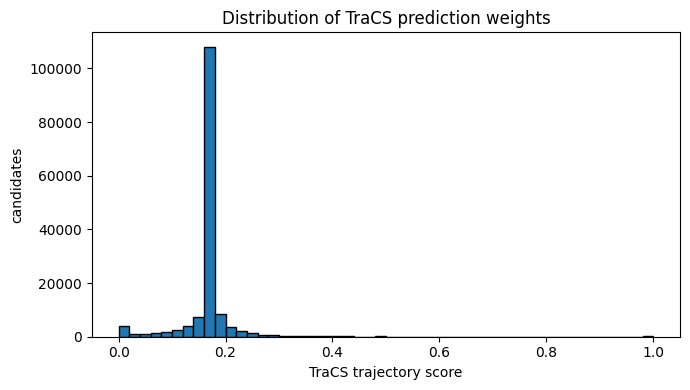

mean=0.1667  std=0.0651  min=0.0000  p25=0.1666  p50=0.1667  p75=0.1677  max=1.0000


In [11]:
tracs_scores = train_data["tracs_trajectory_score"].values.reshape(-1, 6)

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(tracs_scores.flatten(), bins=50, edgecolor="black")
ax.set_xlabel("TraCS trajectory score")
ax.set_ylabel("candidates")
ax.set_title("Distribution of TraCS prediction weights")
plt.tight_layout()
plt.show()

v = tracs_scores.flatten()
print(f"mean={v.mean():.4f}  std={v.std():.4f}  min={v.min():.4f}  "
      f"p25={np.percentile(v,25):.4f}  p50={np.percentile(v,50):.4f}  "
      f"p75={np.percentile(v,75):.4f}  max={v.max():.4f}")

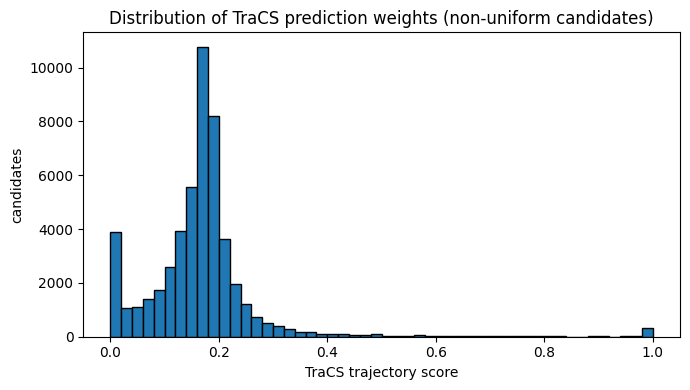

mean=0.1667  std=0.1120  min=0.0000  p25=0.1255  p50=0.1715  p75=0.1926  max=1.0000


In [12]:
tracs_scores_nonuniform = tracs_scores[tracs_scores.std(axis=1) > 0.01, :].flatten()

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(tracs_scores_nonuniform, bins=50, edgecolor="black")
ax.set_xlabel("TraCS trajectory score")
ax.set_ylabel("candidates")
ax.set_title("Distribution of TraCS prediction weights (non-uniform candidates)")
plt.tight_layout()
plt.show()

v = tracs_scores_nonuniform
print(f"mean={v.mean():.4f}  std={v.std():.4f}  min={v.min():.4f}  "
      f"p25={np.percentile(v,25):.4f}  p50={np.percentile(v,50):.4f}  "
      f"p75={np.percentile(v,75):.4f}  max={v.max():.4f}")

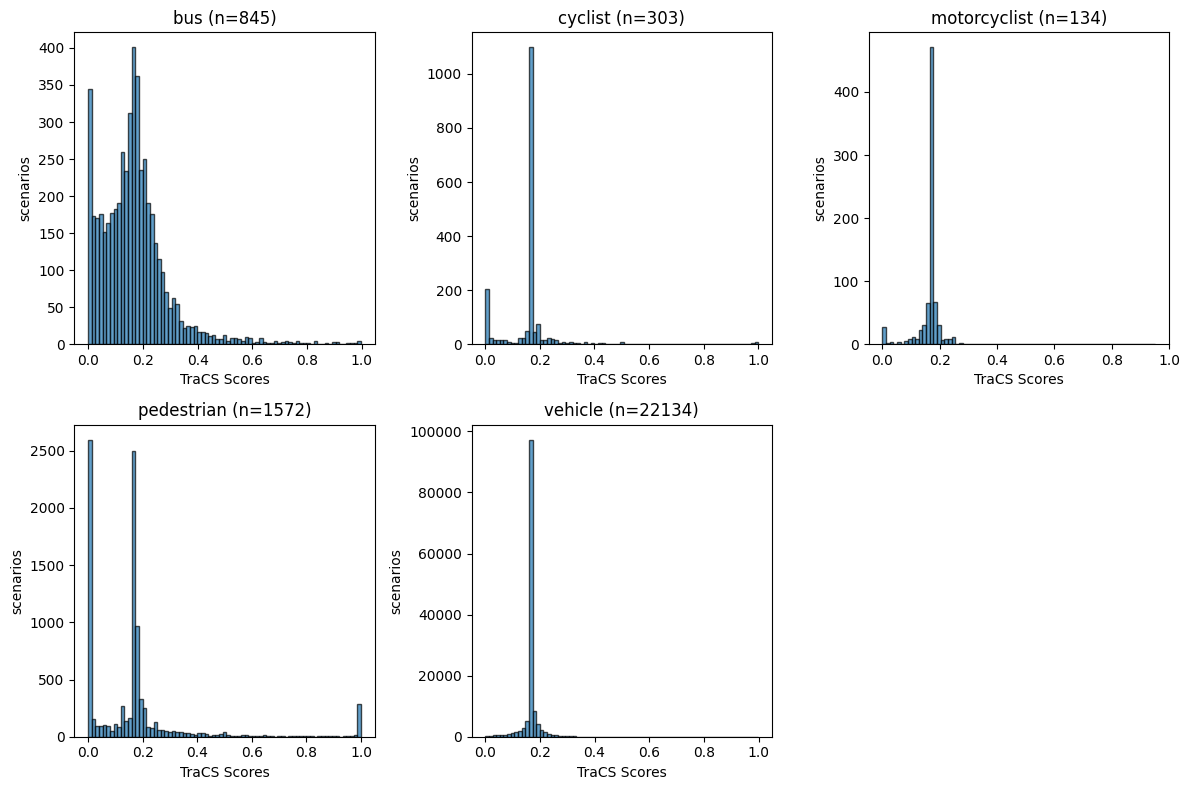

In [13]:
# The same plot as before but split by vehicle type
plt.figure(figsize=(12, 8))
agent_types = train_data["agent_type"].values[::6]
for i, vtype in enumerate(sorted(set(agent_types))):
    plt.subplot(2, 3, i+1)
    mask = agent_types == vtype
    agent_tracs_scores = tracs_scores[mask, :]
    plt.hist(agent_tracs_scores.flatten(), bins=75, edgecolor="black", alpha=0.7)
    plt.xlabel("TraCS Scores")
    plt.ylabel("scenarios")
    plt.title(f"{vtype} (n={mask.sum()})")
plt.tight_layout()
plt.show()

In [ ]:
train_emb = pd.read_parquet(train_embedding_path).set_index("scenario_id")


def _process_scenario(args):
    scenario_id, scenario_data = args
    gt_row = val_gt.loc[scenario_id]
    gt_track = np.stack([
        np.array(gt_row["gt_trajectory_x"]),
        np.array(gt_row["gt_trajectory_y"])
    ], axis=1).astype(np.float64)

    log_tracs_scores = np.log(np.array(scenario_data["tracs_trajectory_score"]) + 1e-10)
    log_backbone_scores = np.log(np.array(scenario_data["backbone_trajectory_score"]) + 1e-10)
    predicted_tracks = np.moveaxis(
        np.array([[*scenario_data["x_traj"]], [*scenario_data["y_traj"]]]),
        source=[0, 1, 2], destination=[2, 0, 1],
    ).astype(np.float64)

    # For ablation: use random TraCS scores instead of the actual ones
    if use_random_tracs_scores and entropy(scenario_data["tracs_trajectory_score"], base=2) < 0.95 * entropy([1/6]*6, base=2):
        log_tracs_scores = np.random.choice(np.arange(6), replace=False, size=6).astype(np.float64)
        log_tracs_scores /= log_tracs_scores.sum()  # normalize to sum to 1
        log_tracs_scores = np.log(log_tracs_scores + 1e-10)

    # past_xy, n_agents = load_scenario_extras(scenario_id, split="val")
    w, original_score, optimal_score = optimal_weights_grid(log_tracs_scores, log_backbone_scores, predicted_tracks, gt_track)

    emb_row = train_emb.loc[scenario_id]
    embedding = np.concatenate([emb_row["focal_embedding"], emb_row["average_embedding"]]).astype(np.float32)

    features = FusionNet.extract_features(
        predicted_tracks,
        focal_type=scenario_data["agent_type"].iloc[0],
        backbone_scores=np.array(scenario_data["backbone_trajectory_score"]),
        tracs_scores=np.array(scenario_data["tracs_trajectory_score"]),
        # n_agents=n_agents,
        # past_trajectory=past_xy,
        embedding=embedding,
    )
    return features, w, original_score, optimal_score


if not features_pt_path.exists() or not optimal_weights_pt_path.exists() or not scores_pt_path.exists():
    groups = list(train_data.groupby("scenario_id"))
    with ThreadPoolExecutor(8) as pool:
        results = list(tqdm.tqdm(pool.map(_process_scenario, groups), total=len(groups)))

    all_features, all_weights, all_original_scores, all_optimal_scores = zip(*results)
    F = torch.tensor(np.stack(all_features), dtype=torch.float32)
    W = torch.tensor(np.array(all_weights), dtype=torch.float32)
    all_original_scores = torch.tensor(np.array(all_original_scores), dtype=torch.float32)
    all_optimal_scores = torch.tensor(np.array(all_optimal_scores), dtype=torch.float32)
    print(f"Dataset: {F.shape} features, {W.shape} labels")

    torch.save(F, features_pt_path)
    torch.save(W, optimal_weights_pt_path)
    torch.save((all_original_scores, all_optimal_scores), scores_pt_path)

else:
    F = torch.load(features_pt_path, weights_only=True)
    W = torch.load(optimal_weights_pt_path, weights_only=True)
    all_original_scores, all_optimal_scores = torch.load(scores_pt_path)

    F.shape, W.shape, len(all_original_scores), len(all_optimal_scores)

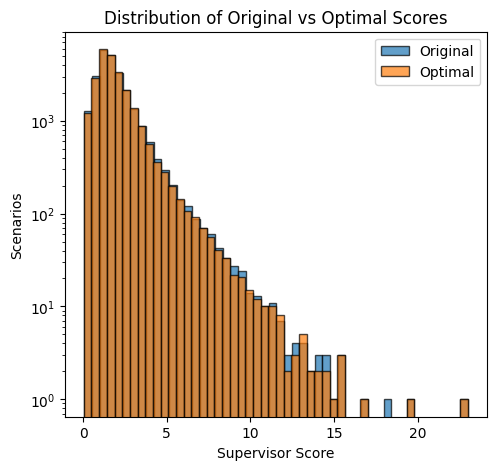

Original scores: mean=2.0036, std=1.4128
Optimal scores: mean=1.9620, std=1.3839
Improvement: mean=0.0416, std=0.1859


In [15]:
# Show histogram of original and optimal scores
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.hist(all_original_scores, bins=50, alpha=0.7, label="Original", edgecolor="black", log=True)
plt.hist(all_optimal_scores, bins=50, alpha=0.7, label="Optimal", edgecolor="black", log=True)
plt.xlabel("Supervisor Score")
plt.ylabel("Scenarios")
plt.title("Distribution of Original vs Optimal Scores")
plt.legend()
plt.show()

print(f"Original scores: mean={np.mean(all_original_scores.numpy()):.4f}, std={np.std(all_original_scores.numpy()):.4f}")
print(f"Optimal scores: mean={np.mean(all_optimal_scores.numpy()):.4f}, std={np.std(all_optimal_scores.numpy()):.4f}")
print(f"Improvement: mean={np.mean(np.array(all_original_scores.numpy()) - np.array(all_optimal_scores.numpy())):.4f}, "
        f"std={np.std(np.array(all_original_scores.numpy()) - np.array(all_optimal_scores.numpy())):.4f}")

bus - Improvement: mean=0.0345, std=0.1109
cyclist - Improvement: mean=0.0456, std=0.1320
motorcyclist - Improvement: mean=0.0319, std=0.1124
pedestrian - Improvement: mean=0.0492, std=0.4157
vehicle - Improvement: mean=0.0414, std=0.1610


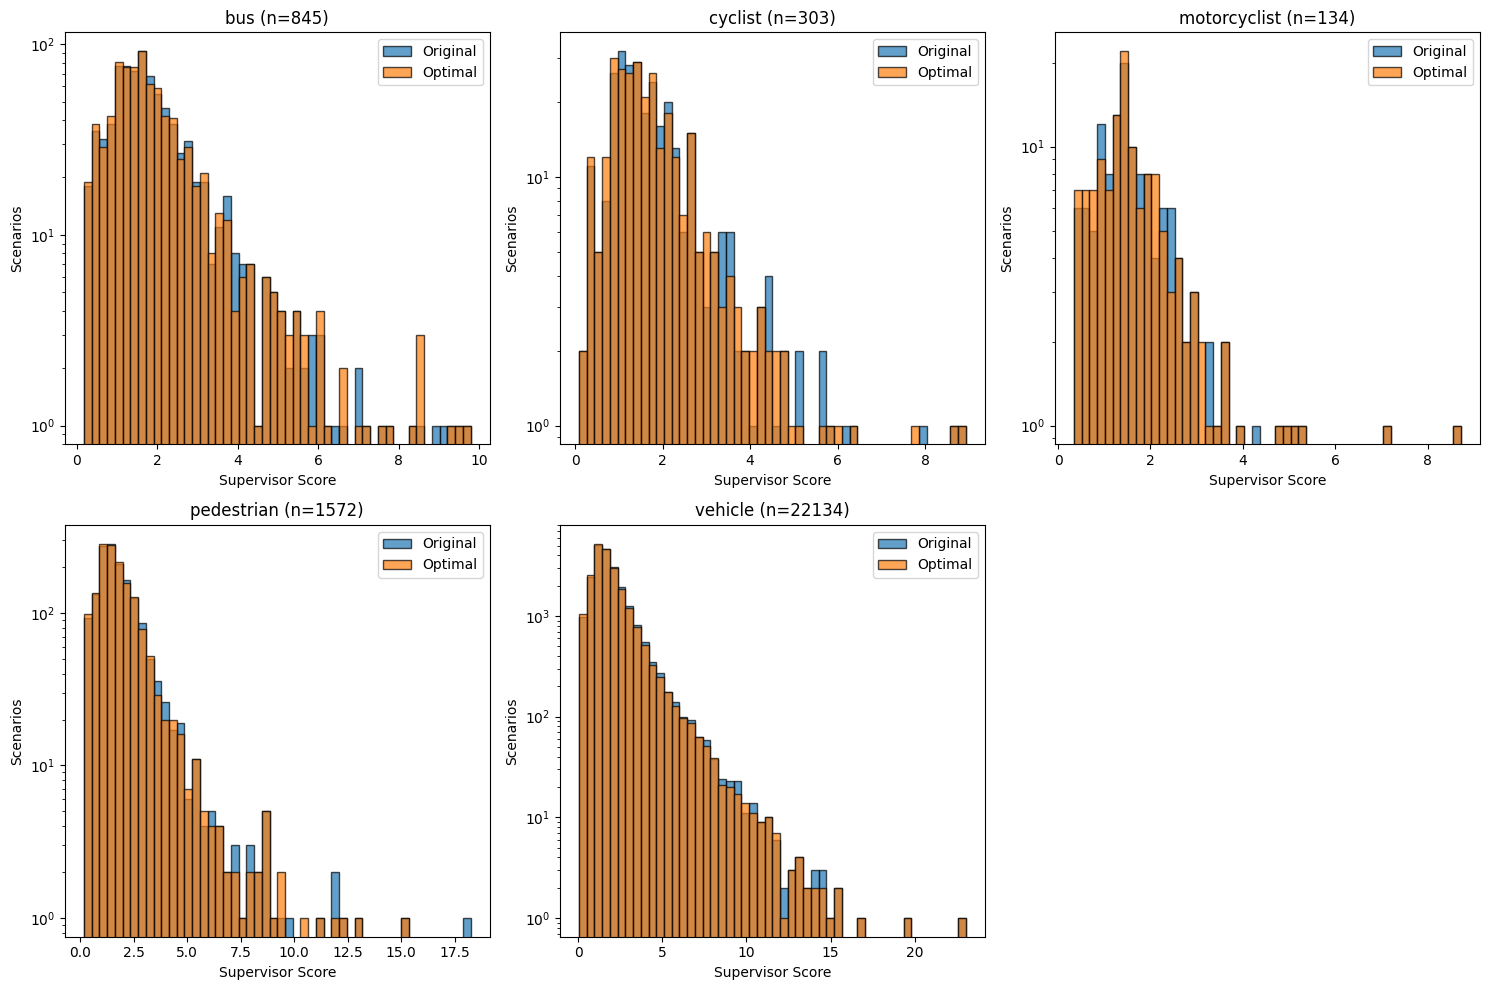

In [16]:
# the same per agent type
agent_types = train_data["agent_type"].values[::6]
plt.figure(figsize=(15, 10))
for i, vtype in enumerate(sorted(set(agent_types))):
    plt.subplot(2, 3, i+1)
    mask = agent_types == vtype
    bins = np.histogram_bin_edges(
        np.concatenate([all_original_scores.numpy()[mask], all_optimal_scores.numpy()[mask]]),
        bins=50,
    )
    plt.hist(all_original_scores.numpy()[mask], bins=bins, alpha=0.7, label="Original", edgecolor="black", log=True)
    plt.hist(all_optimal_scores.numpy()[mask], bins=bins, alpha=0.7, label="Optimal", edgecolor="black", log=True)
    plt.xlabel("Supervisor Score")
    plt.ylabel("Scenarios")
    plt.title(f"{vtype} (n={mask.sum()})")
    plt.legend()
    print(f"{vtype} - Improvement: mean={np.mean(all_original_scores.numpy()[mask] - all_optimal_scores.numpy()[mask]):.4f}, "
          f"std={np.std(all_original_scores.numpy()[mask] - all_optimal_scores.numpy()[mask]):.4f}")
plt.tight_layout()
plt.show()

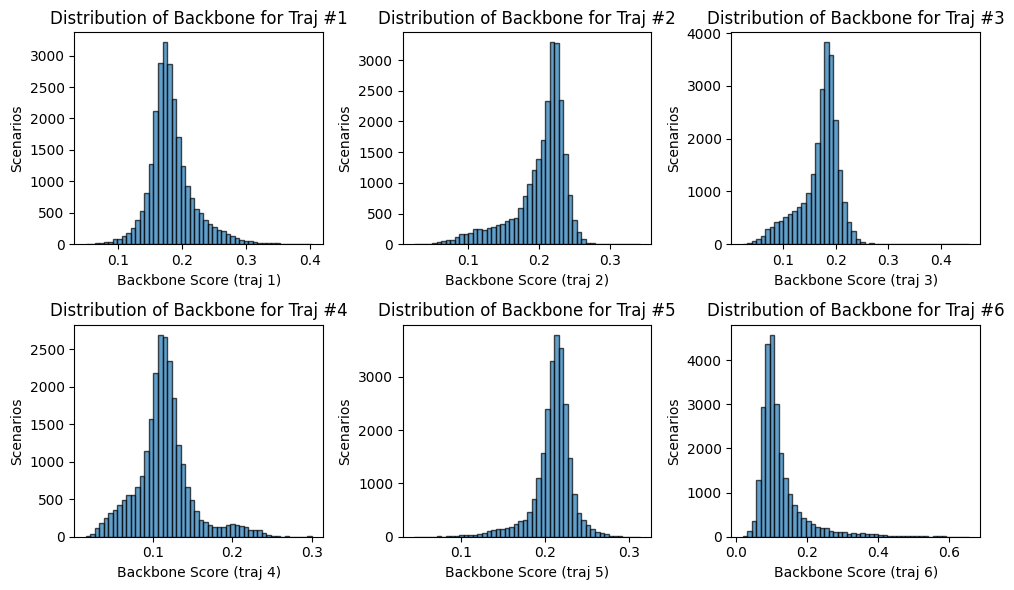

In [17]:
all_backbone_scores = train_data["backbone_trajectory_score"].to_numpy().reshape(-1, 6)

# show average score per each of six indices (shared axes)
plt.figure(figsize=(10, 6))
plt.subplot(2, 3, 1)
for i in range(6):
    plt.subplot(2, 3, i+1)
    plt.hist(all_backbone_scores[:, i], bins=50, edgecolor="black", alpha=0.7)
    plt.xlabel(f"Backbone Score (traj {i+1})")
    plt.ylabel("Scenarios")
    plt.title(f"Distribution of Backbone for Traj #{i+1}")
plt.tight_layout()

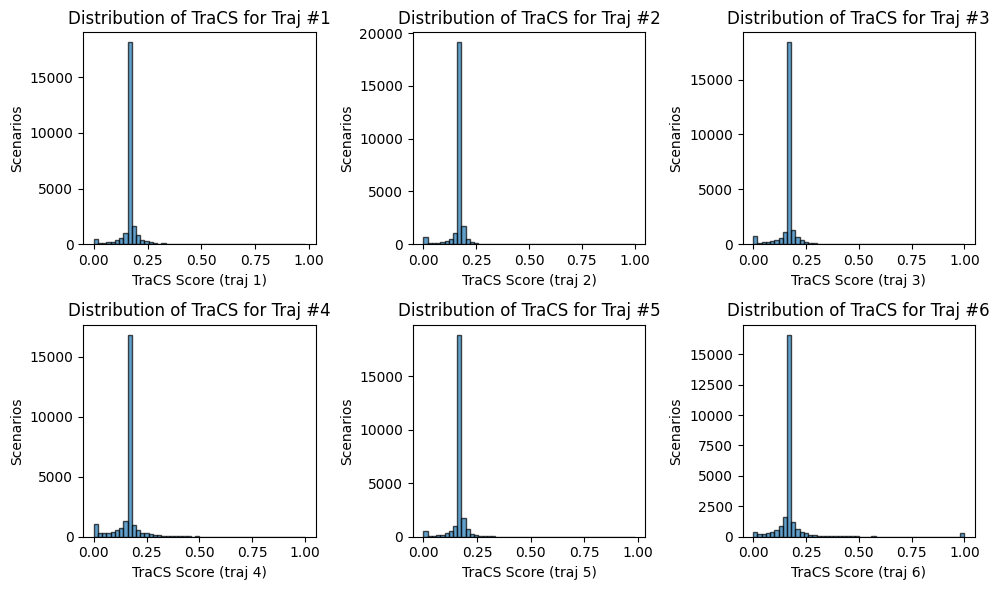

In [18]:
all_traj_scores = train_data["tracs_trajectory_score"].to_numpy().reshape(-1, 6)

# show average score per each of six indices (shared axes)
plt.figure(figsize=(10, 6))
plt.subplot(2, 3, 1)
for i in range(6):
    plt.subplot(2, 3, i+1)
    plt.hist(all_traj_scores[:, i], bins=50, edgecolor="black", alpha=0.7)
    plt.xlabel(f"TraCS Score (traj {i+1})")
    plt.ylabel("Scenarios")
    plt.title(f"Distribution of TraCS for Traj #{i+1}")
plt.tight_layout()

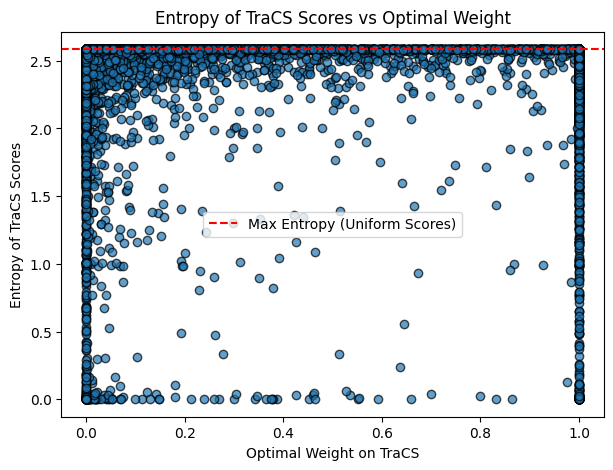

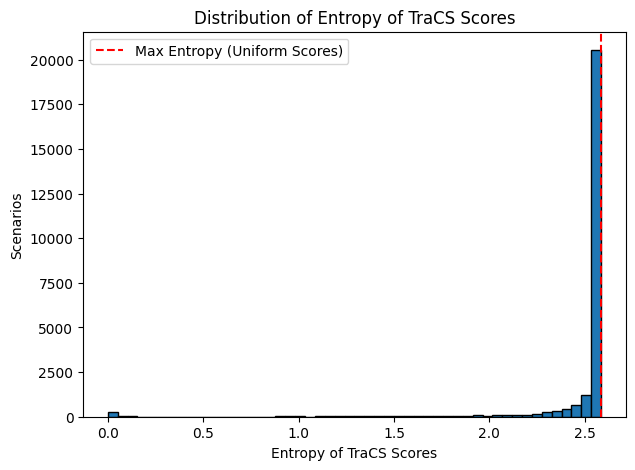

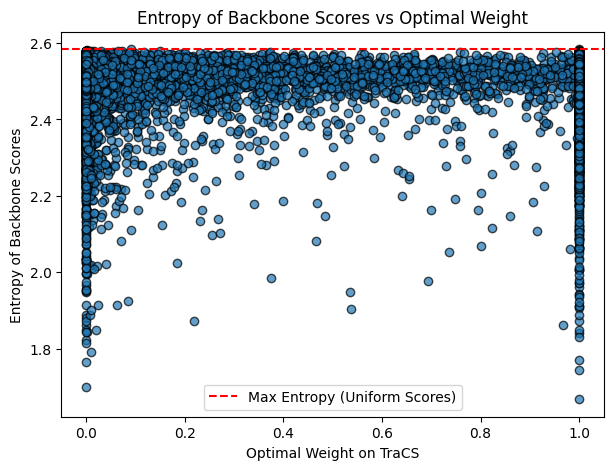

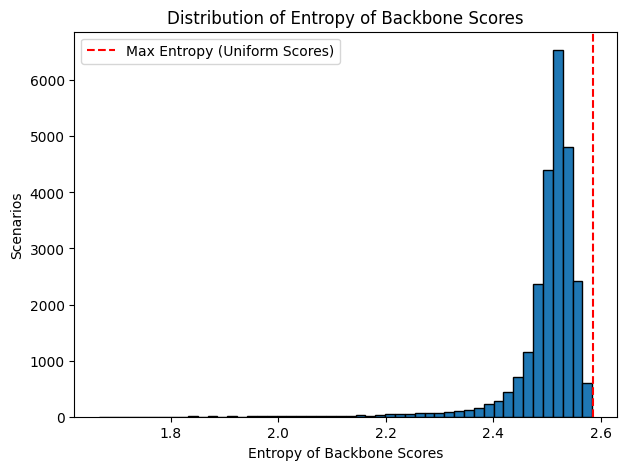

In [19]:
# Show how W correlates with entropy of TraCS scores

entropies_tracs = entropy(train_data["tracs_trajectory_score"].to_numpy().reshape(-1, 6), base=2, axis=-1)
plt.figure(figsize=(7, 5))
plt.scatter(W.cpu().numpy(), entropies_tracs, alpha=0.7, edgecolor="black")
plt.xlabel("Optimal Weight on TraCS")
plt.ylabel("Entropy of TraCS Scores")
plt.axhline(entropy([1/6]*6, base=2), color="red", linestyle="--", label="Max Entropy (Uniform Scores)")
plt.legend()
plt.title("Entropy of TraCS Scores vs Optimal Weight")
plt.show()

plt.figure(figsize=(7, 5))
plt.hist(entropies_tracs, bins=50, edgecolor="black")
plt.xlabel("Entropy of TraCS Scores")
plt.ylabel("Scenarios")
plt.title("Distribution of Entropy of TraCS Scores")
plt.axvline(entropy([1/6]*6, base=2), color="red", linestyle="--", label="Max Entropy (Uniform Scores)")
plt.legend()
plt.show()

entropies_backbone = entropy(train_data["backbone_trajectory_score"].to_numpy().reshape(-1, 6), base=2, axis=-1)
plt.figure(figsize=(7, 5))
plt.scatter(W.cpu().numpy(), entropies_backbone, alpha=0.7, edgecolor="black")
plt.xlabel("Optimal Weight on TraCS")
plt.ylabel("Entropy of Backbone Scores")
plt.axhline(entropy([1/6]*6, base=2), color="red", linestyle="--", label="Max Entropy (Uniform Scores)")
plt.legend()
plt.title("Entropy of Backbone Scores vs Optimal Weight")
plt.show()

plt.figure(figsize=(7, 5))
plt.hist(entropies_backbone, bins=50, edgecolor="black")
plt.xlabel("Entropy of Backbone Scores")
plt.ylabel("Scenarios")
plt.title("Distribution of Entropy of Backbone Scores")
plt.axvline(entropy([1/6]*6, base=2), color="red", linestyle="--", label="Max Entropy (Uniform Scores)")
plt.legend()
plt.show()

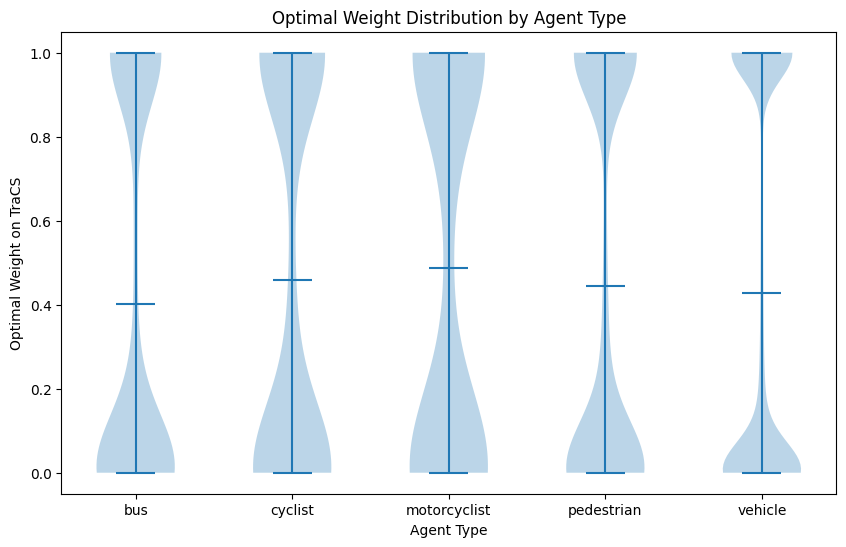

In [20]:
# Show weight distribution by agent type as violin plot

plt.figure(figsize=(10, 6))
agent_types = train_data["agent_type"].values[::6]
plt.violinplot([W[agent_types == vtype].cpu().numpy() for vtype in sorted(set(agent_types))], showmeans=True)
plt.xticks(ticks=np.arange(1, len(set(agent_types))+1), labels=sorted(set(agent_types)))
plt.xlabel("Agent Type")
plt.ylabel("Optimal Weight on TraCS")
plt.title("Optimal Weight Distribution by Agent Type")
plt.show()

/tmp/ipykernel_16433/3242498761.py:2: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearman_scores = np.array([spearmanr(all_backbone_scores[i], all_traj_scores[i]).correlation for i in range(len(all_backbone_scores))])


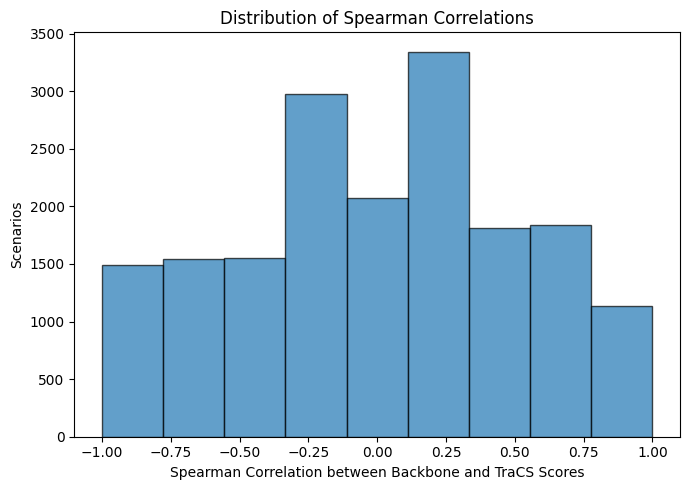

In [21]:
# plot hist over spearmans (each spearman is only over the six trajectories, i.e., axis #1 not axis #0) between backbone and tracs scores
spearman_scores = np.array([spearmanr(all_backbone_scores[i], all_traj_scores[i]).correlation for i in range(len(all_backbone_scores))])
plt.figure(figsize=(7, 5))
plt.hist(spearman_scores, bins=9, edgecolor="black", alpha=0.7)
plt.xlabel("Spearman Correlation between Backbone and TraCS Scores")
plt.ylabel("Scenarios")
plt.title("Distribution of Spearman Correlations")
plt.tight_layout()
plt.show()

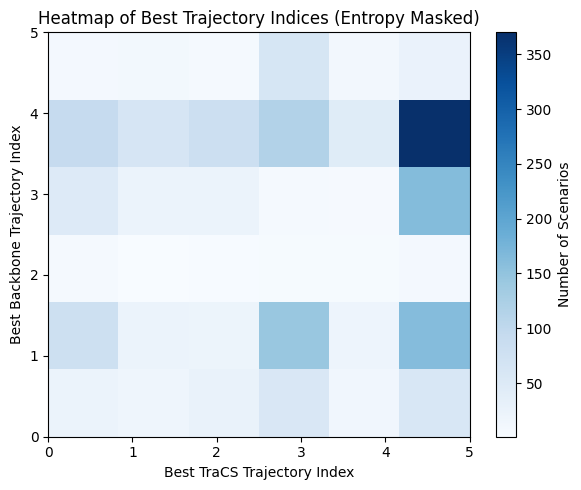

7.415559468544902

In [22]:
idx_best_traj = tracs_scores.argmax(axis=-1)
# idx_best_traj = np.random.randint(0, 6, size=all_traj_scores.shape[0])  # for testing the heatmap with random indices
idx_best_score = all_backbone_scores.argmax(axis=-1)

mask = entropy(tracs_scores, base=2, axis=-1) < 0.9 * entropy([1/6]*6, base=2)
plt.figure(figsize=(6, 5))
plt.hist2d(idx_best_traj[mask], idx_best_score[mask], bins=6, range=[[0, 5], [0, 5]], cmap="Blues")
plt.xlabel("Best TraCS Trajectory Index")
plt.ylabel("Best Backbone Trajectory Index")
plt.title("Heatmap of Best Trajectory Indices (Entropy Masked)")
plt.colorbar(label="Number of Scenarios")
plt.tight_layout()
plt.show()

# show percentage of retained scenarios after applying the entropy-based mask
mask.sum().item() / len(mask) * 100

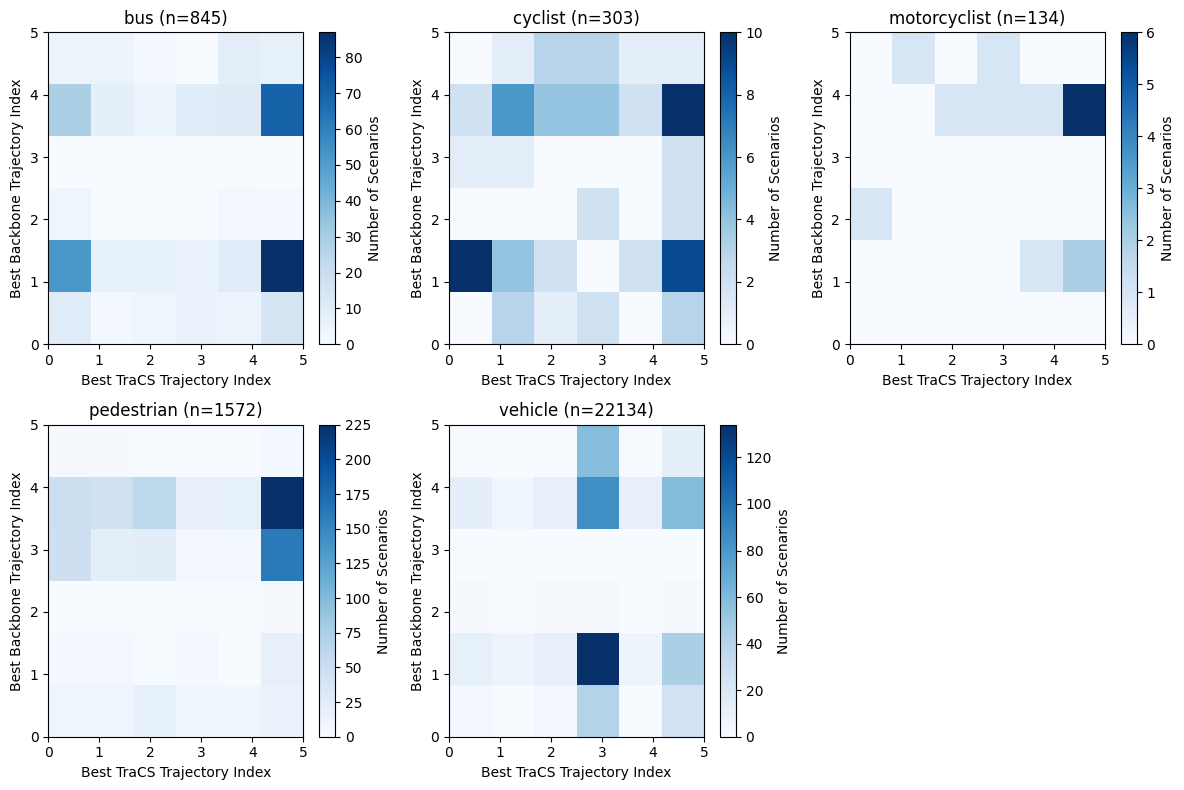

In [23]:
# same per agent type

agent_types = train_data["agent_type"].values[::6]
plt.figure(figsize=(12, 8))
for i, vtype in enumerate(sorted(set(agent_types))):
    plt.subplot(2, 3, i+1)
    vtype_mask = agent_types == vtype
    mask = (entropy(tracs_scores[vtype_mask], base=2, axis=-1) < 0.9 * entropy([1/6]*6, base=2))
    plt.hist2d(idx_best_traj[vtype_mask][mask], idx_best_score[vtype_mask][mask], bins=6, range=[[0, 5], [0, 5]], cmap="Blues")
    plt.xlabel("Best TraCS Trajectory Index")
    plt.ylabel("Best Backbone Trajectory Index")
    plt.title(f"{vtype} (n={vtype_mask.sum()})")
    plt.colorbar(label="Number of Scenarios")
plt.tight_layout()
plt.show()

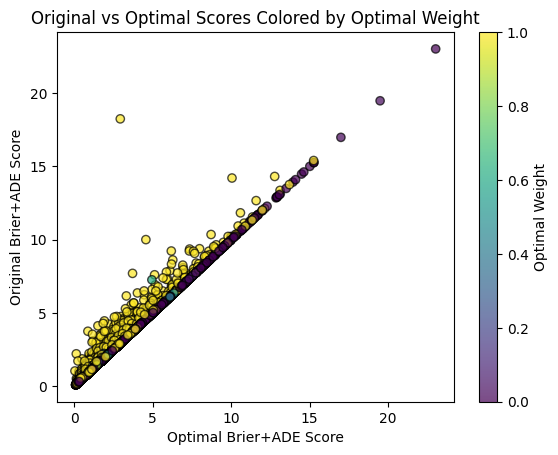

In [24]:
plt.scatter(all_optimal_scores, all_original_scores, alpha=0.7, edgecolor="black", c=W)
plt.xlabel("Optimal Brier+ADE Score")
plt.ylabel("Original Brier+ADE Score")
plt.title("Original vs Optimal Scores Colored by Optimal Weight")
plt.colorbar(label="Optimal Weight")
plt.show()

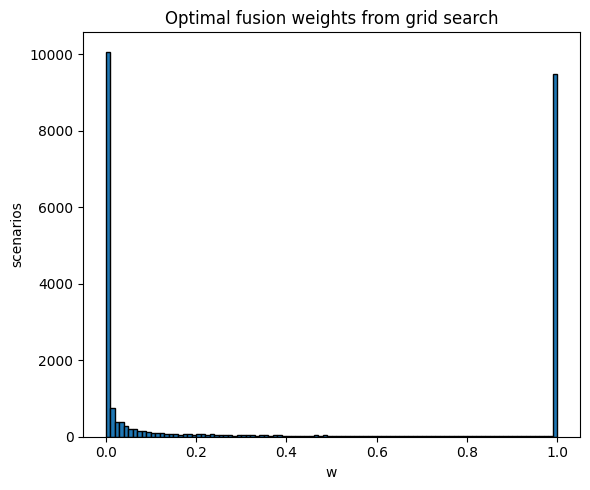

                      mean     std     min     p25     p50     p75     max
 0.429   0.470   0.000   0.000   0.084   1.000   1.000


In [25]:
w_np = W.cpu().numpy()
fig, ax = plt.subplots(figsize=(6, 5))
plt.hist(w_np, bins=100, edgecolor="black")
ax.set_xlabel("w")
ax.set_ylabel("scenarios")
ax.set_title("Optimal fusion weights from grid search")
plt.tight_layout()
plt.show()

header = f"{'':18s}  {'mean':>6}  {'std':>6}  {'min':>6}  {'p25':>6}  {'p50':>6}  {'p75':>6}  {'max':>6}"
print(header)
print(f"{w_np.mean():6.3f}  {w_np.std():6.3f}  {w_np.min():6.3f}  "
        f"{np.percentile(w_np,25):6.3f}  {np.percentile(w_np,50):6.3f}  "
        f"{np.percentile(w_np,75):6.3f}  {w_np.max():6.3f}")

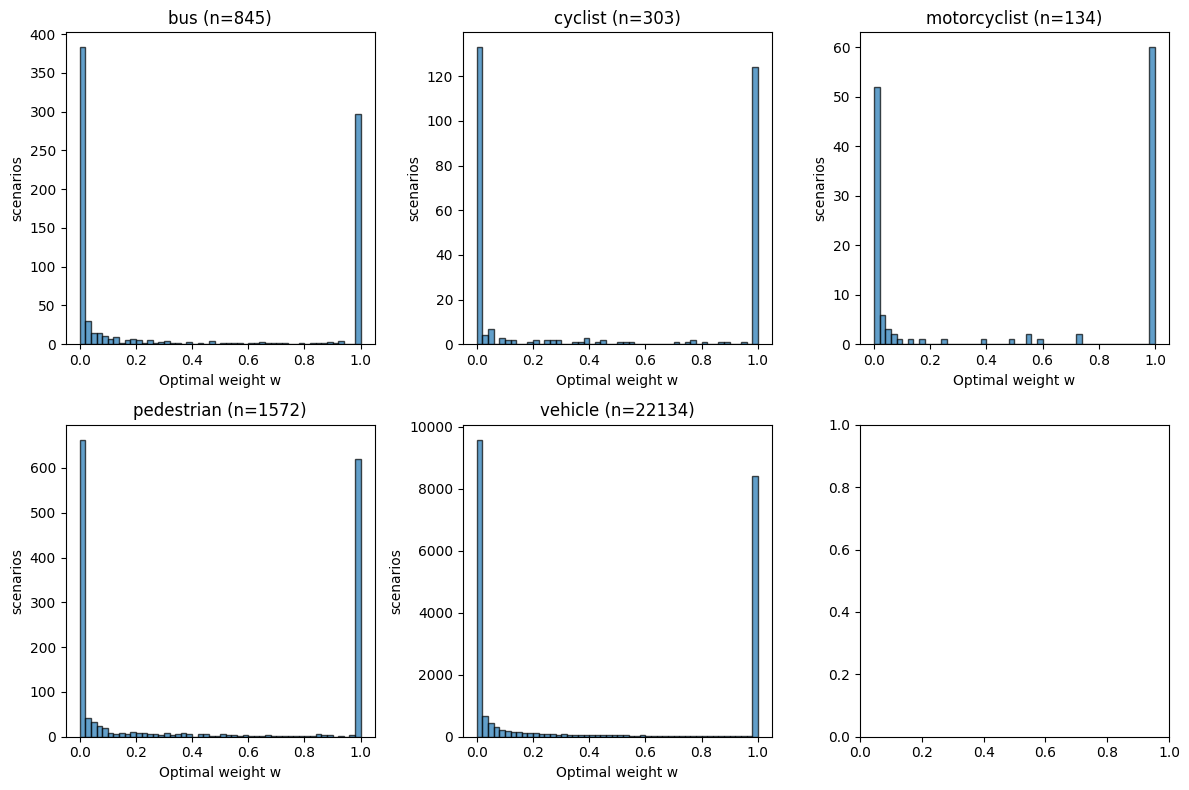

In [26]:
# now split by agent type since some types have very few samples (e.g. bus)
plt.subplots(2, 3, figsize=(12, 8))
agent_types = train_data["agent_type"].values[::6]
for i, vtype in enumerate(sorted(set(agent_types))):
    plt.subplot(2, 3, i+1)
    mask = agent_types == vtype
    plt.hist(w_np[mask], bins=50, edgecolor="black", alpha=0.7)
    plt.xlabel("Optimal weight w")
    plt.ylabel("scenarios")
    plt.title(f"{vtype} (n={mask.sum()})")
plt.tight_layout()
plt.show()

In [27]:
# TODO show the above without the uniform cases

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
F, W = F.to(device), W.to(device)

# Deterministic 90/10 train/val split by scenario index
g = torch.Generator(device="cpu").manual_seed(0)
perm = torch.randperm(len(F), generator=g)
n_val = int(0.1 * len(F))
val_idx = perm[:n_val].to(device)
train_idx = perm[n_val:].to(device)
F_tr, W_tr = F[train_idx], W[train_idx]
F_va, W_va = F[val_idx], W[val_idx]
print(f"Train: {len(F_tr)}  Val: {len(F_va)}")

n_epochs = 500
patience = 30
min_delta = 1e-5

model = FusionNet(F.shape[1]).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=15, min_lr=1e-6
)

best_val_loss = float("inf")
best_state = None
patience_counter = 0

train_losses = []
val_losses = []

for epoch in range(n_epochs):
    model.train()
    for idx in torch.randperm(len(F_tr)).split(256):
        optimizer.zero_grad()
        nn.functional.binary_cross_entropy(model(F_tr[idx]), W_tr[idx]).backward()
        optimizer.step()

    model.eval()
    with torch.no_grad():
        tr_loss = nn.functional.binary_cross_entropy(model(F_tr), W_tr).item()
        va_loss = nn.functional.binary_cross_entropy(model(F_va), W_va).item()

    scheduler.step(va_loss)
    train_losses.append(tr_loss)
    val_losses.append(va_loss)

    improved = va_loss < best_val_loss - min_delta
    if improved:
        best_val_loss = va_loss
        best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        patience_counter = 0
    else:
        patience_counter += 1

    if epoch % 10 == 0 or improved:
        lr = optimizer.param_groups[0]["lr"]
        tag = " *" if improved else ""
        print(f"Epoch {epoch:3d}: train={tr_loss:.4f}  val={va_loss:.4f}  "
              f"lr={lr:.2e}  patience={patience_counter}/{patience}{tag}")

    if patience_counter >= patience:
        print(f"\nEarly stopping at epoch {epoch} — best val={best_val_loss:.4f}")
        break

model.load_state_dict({k: v.to(device) for k, v in best_state.items()})
print(f"Restored best model weights (val={best_val_loss:.4f})")

Train: 22490  Val: 2498
Epoch   0: train=0.5721  val=0.5729  lr=1.00e-03  patience=0/30 *
Epoch   1: train=0.5507  val=0.5535  lr=1.00e-03  patience=0/30 *
Epoch   2: train=0.5426  val=0.5464  lr=1.00e-03  patience=0/30 *
Epoch   3: train=0.5374  val=0.5433  lr=1.00e-03  patience=0/30 *
Epoch   4: train=0.5351  val=0.5402  lr=1.00e-03  patience=0/30 *
Epoch   5: train=0.5292  val=0.5394  lr=1.00e-03  patience=0/30 *
Epoch   6: train=0.5266  val=0.5357  lr=1.00e-03  patience=0/30 *
Epoch   7: train=0.5224  val=0.5349  lr=1.00e-03  patience=0/30 *
Epoch   8: train=0.5205  val=0.5324  lr=1.00e-03  patience=0/30 *
Epoch   9: train=0.5169  val=0.5299  lr=1.00e-03  patience=0/30 *
Epoch  10: train=0.5157  val=0.5292  lr=1.00e-03  patience=0/30 *
Epoch  12: train=0.5114  val=0.5280  lr=1.00e-03  patience=0/30 *
Epoch  13: train=0.5081  val=0.5262  lr=1.00e-03  patience=0/30 *
Epoch  16: train=0.5038  val=0.5254  lr=1.00e-03  patience=0/30 *
Epoch  20: train=0.4970  val=0.5284  lr=1.00e-03  pa

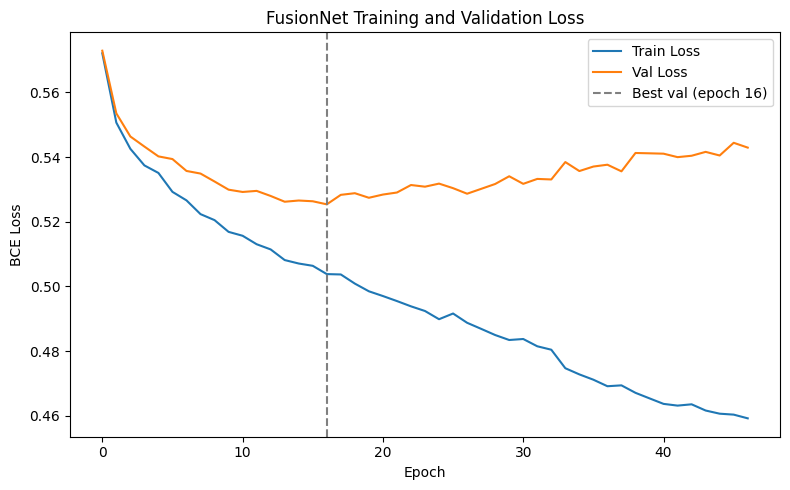

In [48]:
plt.figure(figsize=(8, 5))
epochs_recorded = range(len(train_losses))
plt.plot(epochs_recorded, train_losses, label="Train Loss")
plt.plot(epochs_recorded, val_losses, label="Val Loss")
best_epoch = int(np.argmin(val_losses))
plt.axvline(best_epoch, color="gray", linestyle="--", label=f"Best val (epoch {best_epoch})")
plt.xlabel("Epoch")
plt.ylabel("BCE Loss")
plt.title("FusionNet Training and Validation Loss")
plt.legend()
plt.tight_layout()
plt.show()

In [49]:
# --- Select fusion threshold on the held-out val split (not test) ---
# Arrays are rebuilt in groupby order so they align row-for-row with F.
model.eval()
with torch.no_grad():
    w_all = model(F).cpu().numpy()          # predicted weight per training scenario, aligned with F

ade_rows, bb_rows, tr_rows, agent_rows = [], [], [], []
for scenario_id, sd in tqdm.tqdm(train_data.groupby("scenario_id")):
    gt_row = val_gt.loc[scenario_id]
    gt_track = np.stack([np.array(gt_row["gt_trajectory_x"]),
                         np.array(gt_row["gt_trajectory_y"])], axis=1).astype(np.float64)
    predicted_tracks = np.moveaxis(
        np.array([[*sd["x_traj"]], [*sd["y_traj"]]]),
        source=[0, 1, 2], destination=[2, 0, 1]).astype(np.float64)
    bb = np.array(sd["backbone_trajectory_score"], dtype=np.float64)
    ade_rows.append(metrics.compute_ade(predicted_tracks, gt_track))
    bb_rows.append(bb / bb.sum())
    tr_rows.append(np.array(sd["tracs_trajectory_score"], dtype=np.float64))
    agent_rows.append(sd["agent_type"].iloc[0])

ade_all, bb_all, tr_all = np.stack(ade_rows), np.stack(bb_rows), np.stack(tr_rows)
agent_all = np.array(agent_rows)

# Restrict to the held-out val split
va = val_idx.cpu().numpy()
log_bb, log_tr, ulo = np.log(bb_all[va] + 1e-10), np.log(tr_all[va] + 1e-10), np.log(1/6)
ade_va, w_va, agent_va = ade_all[va], w_all[va], agent_all[va]
vtypes = sorted(set(agent_va))

def brier(w):
    fused = log_bb + w[:, None] * (log_tr - ulo)
    fused = np.exp(fused - fused.max(1, keepdims=True)); fused /= fused.sum(1, keepdims=True)
    idx = fused.argmax(1)
    sel = np.take_along_axis(fused, idx[:, None], 1).squeeze(1)
    sel_ade = np.take_along_axis(ade_va, idx[:, None], 1).squeeze(1)
    return sel_ade + (1 - sel) ** 2

bb_score = brier(np.zeros(len(w_va)))
def overall(w):  return brier(w).mean() - bb_score.mean()
def balanced(w):
    fb = brier(w)
    return np.mean([fb[agent_va == v].mean() - bb_score[agent_va == v].mean() for v in vtypes])

thresholds = np.round(np.arange(0.30, 0.96, 0.05), 2)
print(f"VAL split (n={len(va)})  backbone brier_minADE1 = {bb_score.mean():.4f}\n")
print(f"{'thresh':>7} | {'continuous Δ':>13} {'bal':>9} | {'snap-to-1 Δ':>13} {'bal':>9} | {'%fused':>7}")
best = {}
for t in thresholds:
    cont = np.where(w_va >= t, w_va, 0.0)
    binr = np.where(w_va >= t, 1.0, 0.0)
    oc, ob = overall(cont), overall(binr)
    print(f"{t:>7.2f} | {oc:>+13.4f} {balanced(cont):>+9.4f} | "
          f"{ob:>+13.4f} {balanced(binr):>+9.4f} | {(w_va >= t).mean()*100:>6.1f}%")
    best["continuous"] = min(best.get("continuous", (np.inf, None)), (oc, t))
    best["snap-to-1"]  = min(best.get("snap-to-1",  (np.inf, None)), (ob, t))

print("\nBest by overall val Δ:")
for policy, (d, t) in best.items():
    print(f"  {policy:<11} threshold={t:.2f}  val Δ={d:+.4f}")
print(f"\n>>> Set FUSION_WEIGHT_THRESHOLD = {best['snap-to-1'][1]:.2f} (binary policy)")


100%|██████████| 24988/24988 [00:10<00:00, 2376.42it/s]


VAL split (n=2498)  backbone brier_minADE1 = 2.1873

 thresh |  continuous Δ       bal |   snap-to-1 Δ       bal |  %fused
   0.30 |       +0.0082   -0.0179 |       +0.0168   -0.0302 |   61.4%
   0.35 |       +0.0086   -0.0083 |       +0.0189   -0.0155 |   56.8%
   0.40 |       +0.0075   -0.0226 |       +0.0145   -0.0336 |   51.7%
   0.45 |       +0.0050   -0.0226 |       +0.0078   -0.0424 |   47.8%
   0.50 |       +0.0015   -0.0280 |       +0.0021   -0.0527 |   43.9%
   0.55 |       -0.0000   -0.0316 |       -0.0024   -0.0562 |   38.5%
   0.60 |       -0.0030   -0.0283 |       -0.0039   -0.0349 |   32.6%
   0.65 |       +0.0005   -0.0088 |       +0.0011   -0.0099 |   24.3%
   0.70 |       -0.0006   -0.0088 |       -0.0006   -0.0099 |   17.0%
   0.75 |       -0.0004   -0.0066 |       -0.0005   -0.0073 |   11.9%
   0.80 |       -0.0006   -0.0020 |       -0.0004   -0.0021 |    7.3%
   0.85 |       +0.0010   -0.0009 |       +0.0010   -0.0010 |    3.4%
   0.90 |       -0.0000   -0.0007 |  

In [50]:
test_data = pd.read_parquet(test_data_path)
ground_truth = pd.read_parquet(test_ground_truth_path)
test_emb = pd.read_parquet(test_embedding_path).set_index("scenario_id")
rows = []

for scenario_id in tqdm.tqdm(test_data["scenario_id"].unique()):  # TODO remove debugging slice
    gt_row = ground_truth[ground_truth["scenario_id"] == scenario_id]
    gt_track = np.stack([
        np.array(gt_row["gt_trajectory_x"].iloc[0]),
        np.array(gt_row["gt_trajectory_y"].iloc[0])
    ], axis=1).astype(np.float64)

    scenario_data = test_data[test_data["scenario_id"] == scenario_id]
    backbone_probs = np.array(scenario_data["backbone_trajectory_score"], dtype=np.float64)
    tracs_scores = np.array(scenario_data["tracs_trajectory_score"], dtype=np.float64)
    predicted_tracks = np.moveaxis(
        np.array([[*scenario_data["x_traj"]], [*scenario_data["y_traj"]]]),
        source=[0, 1, 2], destination=[2, 0, 1],
    ).astype(np.float64)

    focal_type = scenario_data["agent_type"].iloc[0]
    # past_xy, n_agents = load_scenario_extras(scenario_id, split="test")
    emb_row = test_emb.loc[scenario_id]
    embedding = np.concatenate([emb_row["focal_embedding"], emb_row["average_embedding"]]).astype(np.float32)

    # Backbone only
    backbone_probs_norm = backbone_probs / backbone_probs.sum()

    # FusionNet
    w = model.predict_weights(
        predicted_tracks,
        focal_type=focal_type,
        backbone_scores=backbone_probs,
        tracs_scores=tracs_scores,
        # n_agents=n_agents,
        # past_trajectory=past_xy,
        embedding=embedding,
    )
    # w = w.round()
    # w = w.clip(0, None)
    # if w < 0.1:
    #     w = np.array(0)
    if w < FUSION_WEIGHT_THRESHOLD:
        w = np.array(0.0)   # low confidence → pure backbone
    else:
        w = np.array(1.0)   # high confidence → pure TraCS
    fused_probs = fuse_classifiers(np.log(backbone_probs + 1e-10), np.log(tracs_scores + 1e-10), w)

    # Full AV2 metric set: per-trajectory arrays are shared across weightings
    ade_arr = metrics.compute_ade(predicted_tracks, gt_track)
    fde_arr = metrics.compute_fde(predicted_tracks, gt_track)
    is_missed_arr = metrics.compute_is_missed_prediction(predicted_tracks, gt_track)
    backbone_av2 = compute_weighted_metrics(predicted_tracks, gt_track, backbone_probs_norm, ade_arr, fde_arr, is_missed_arr)
    fusion_av2 = compute_weighted_metrics(predicted_tracks, gt_track, fused_probs, ade_arr, fde_arr, is_missed_arr)

    main_criterion = "brier_minADE1"
    rows.append({
        "scenario_id": scenario_id,
        "agent_type": focal_type,
        "weight": float(w),
        "tracs_scores": tracs_scores,
        **{f"backbone_{k}": v for k, v in backbone_av2.items()},
        **{f"fusion_{k}": v for k, v in fusion_av2.items()},
        "backbone_score": backbone_av2[main_criterion],
        "fusion_score": fusion_av2[main_criterion],
    })

results = pd.DataFrame(rows)
results["delta"] = results["fusion_score"] - results["backbone_score"]

# Categorize per-scenario change as improved / same / degraded (used by the summary and plots).
_tol = 1e-3
results["category"] = pd.Categorical(
    np.select(
        [results["delta"] < -_tol, results["delta"] > _tol],
        ["improved", "degraded"],
        default="same",
    ),
    categories=["improved", "same", "degraded"],
    ordered=True,
)

# Relative entropy of the TraCS distribution (confidence proxy used by downstream plots).
_tracs_arr = np.stack(results["tracs_scores"].to_list())
_uniform_entropy = 6 * -(1/6 * np.log(1/6))
results["tracs_rel_entropy"] = -np.sum(_tracs_arr * np.log(_tracs_arr + 1e-10), axis=1) - _uniform_entropy

  0%|          | 0/24984 [00:00<?, ?it/s]/tmp/ipykernel_16433/2451094780.py:50: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = spearmanr(backbone_scores, tracs_scores).correlation
 38%|███▊      | 9452/24984 [01:01<01:41, 153.06it/s]


KeyboardInterrupt: 

In [ ]:
# Table 1: Brier-minADE summary (overall + per vehicle type)
print(f"Backbone   Brier-minADE: {results['backbone_score'].mean():.4f}")
print(f"FusionNet  Brier-minADE: {results['fusion_score'].mean():.4f}")
print(f"Delta: {results['delta'].mean():.4f}  ({(results['fusion_score'].mean() / results['backbone_score'].mean() - 1) * 100:.1f}%)")
vtypes = sorted(results["agent_type"].unique())
balanced_delta = sum(
    results.loc[results["agent_type"] == vt, "delta"].mean() for vt in vtypes
) / len(vtypes)
print(f"Balanced Delta (avg of per-type deltas): {balanced_delta:.4f}")

print("\nPer vehicle type:")
for vtype in vtypes:
    sub = results[results["agent_type"] == vtype]
    b = sub["backbone_score"].to_numpy()
    f = sub["fusion_score"].to_numpy()
    imp = sub["category"] == "improved"
    same = sub["category"] == "same"
    deg = sub["category"] == "degraded"
    d_improved = sub.loc[imp, "delta"].to_numpy()
    d_degraded = sub.loc[deg, "delta"].to_numpy()
    n = len(sub)
    print(f"  {vtype:14s}  n={n:5d}  Backbone={b.mean():.4f}  FusionNet={f.mean():.4f}  "
          f"Delta={f.mean()-b.mean():+.4f} ({(f.mean()/b.mean()-1)*100:+.1f}%)  "
          f"Improved={imp.sum()/n*100:.1f}%  Same={same.sum()/n*100:.1f}%  Degraded={deg.sum()/n*100:.1f}%  "
          f"Delta(improved)={d_improved.mean():.4f} ({d_improved.mean()/(b[imp].mean())*100:.1f}%)  "
          f"Delta(degraded)={d_degraded.mean():.4f} ({d_degraded.mean()/(b[deg].mean())*100:.1f}%)  "
          f"q90_improvement={np.percentile(f, 90)-np.percentile(b, 90):.4f}")

# Table 2: Full AV2 metrics (overall + per vehicle type)
av2_metric_names = [c[len("backbone_"):] for c in results.columns
                    if c.startswith("backbone_") and c != "backbone_score"]

def _print_av2_table(subset, label):
    print(f"\nFull AV2 metrics — {label}:")
    print(f"  {'metric':<25s} {'Backbone':>10s} {'FusionNet':>10s} {'Delta':>10s}")
    for m in av2_metric_names:
        b = subset[f"backbone_{m}"].mean()
        f = subset[f"fusion_{m}"].mean()
        delta = f - b
        delta_percent = (f / b - 1) * 100
        print(f"  {m:<25s} {b:>10.4f} {f:>10.4f} {delta:>+10.4f} ({delta_percent:>+4.1f}%)")

_print_av2_table(results, f"overall (n={len(results)})")
for vtype in vtypes:
    sub = results[results["agent_type"] == vtype]
    _print_av2_table(sub, f"{vtype} (n={len(sub)})")

Backbone   Brier-minADE: 2.1900
FusionNet  Brier-minADE: 2.1842
Delta: -0.0059  (-0.3%)
Balanced Delta (avg of per-type deltas): -0.0198

Per vehicle type:
  bus             n=  913  Backbone=2.5072  FusionNet=2.4661  Delta=-0.0411 (-1.6%)  Improved=40.6%  Same=45.0%  Degraded=14.3%  Delta(improved)=-0.3902 (-14.2%)  Delta(degraded)=0.8189 (40.6%)  q90_improvement=-0.0630
  cyclist         n=  346  Backbone=1.9574  FusionNet=1.9493  Delta=-0.0081 (-0.4%)  Improved=15.3%  Same=83.8%  Degraded=0.9%  Delta(improved)=-0.0770 (-3.3%)  Delta(degraded)=0.4226 (34.0%)  q90_improvement=0.0000
  motorcyclist    n=  117  Backbone=2.6472  FusionNet=2.6258  Delta=-0.0213 (-0.8%)  Improved=39.3%  Same=58.1%  Degraded=2.6%  Delta(improved)=-0.0879 (-2.5%)  Delta(degraded)=0.5165 (23.4%)  q90_improvement=-0.0001
  pedestrian      n= 1589  Backbone=1.2375  FusionNet=1.2121  Delta=-0.0254 (-2.1%)  Improved=24.5%  Same=73.6%  Degraded=1.9%  Delta(improved)=-0.1132 (-9.1%)  Delta(degraded)=0.1252 (11.4%) 

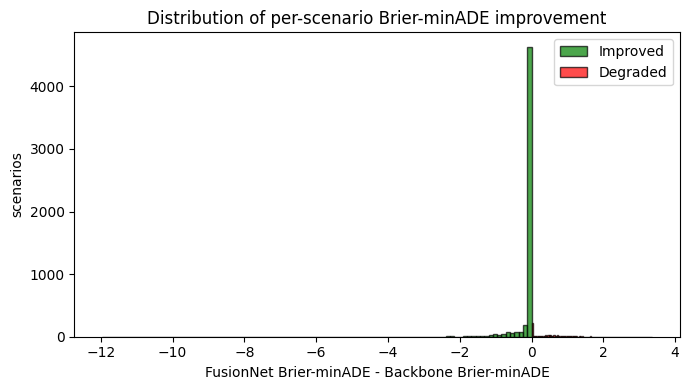

In [ ]:
# Histogram of deltas
plt.figure(figsize=(7, 4))
plt.hist(results.loc[results["category"] == "improved", "delta"], bins=100, edgecolor="black", color="green", alpha=0.7, label="Improved")
plt.hist(results.loc[results["category"] == "degraded", "delta"], bins=100, edgecolor="black", color="red", alpha=0.7, label="Degraded")
plt.xlabel("FusionNet Brier-minADE - Backbone Brier-minADE")
plt.ylabel("scenarios")
plt.title("Distribution of per-scenario Brier-minADE improvement")
plt.legend()
plt.tight_layout()
plt.show()

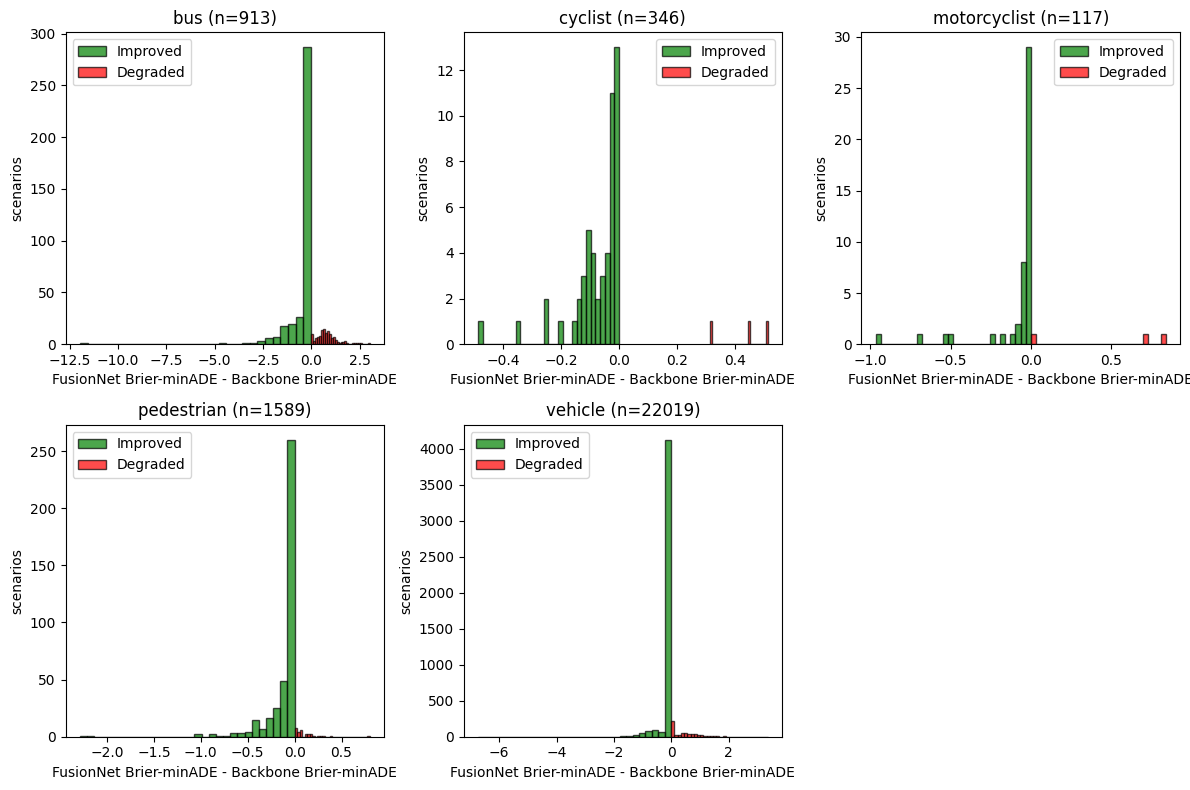

In [ ]:
# The same plot as before but split by vehicle type
plt.figure(figsize=(12, 8))
for i, vtype in enumerate(sorted(results["agent_type"].unique())):
    plt.subplot(2, 3, i+1)
    sub = results[results["agent_type"] == vtype]
    plt.hist(sub.loc[sub["category"] == "improved", "delta"], bins=30, edgecolor="black", color="green", alpha=0.7, label="Improved")
    plt.hist(sub.loc[sub["category"] == "degraded", "delta"], bins=30, edgecolor="black", color="red", alpha=0.7, label="Degraded")
    plt.xlabel("FusionNet Brier-minADE - Backbone Brier-minADE")
    plt.ylabel("scenarios")
    plt.title(f"{vtype} (n={len(sub)})")
    plt.legend()
plt.tight_layout()
plt.show()

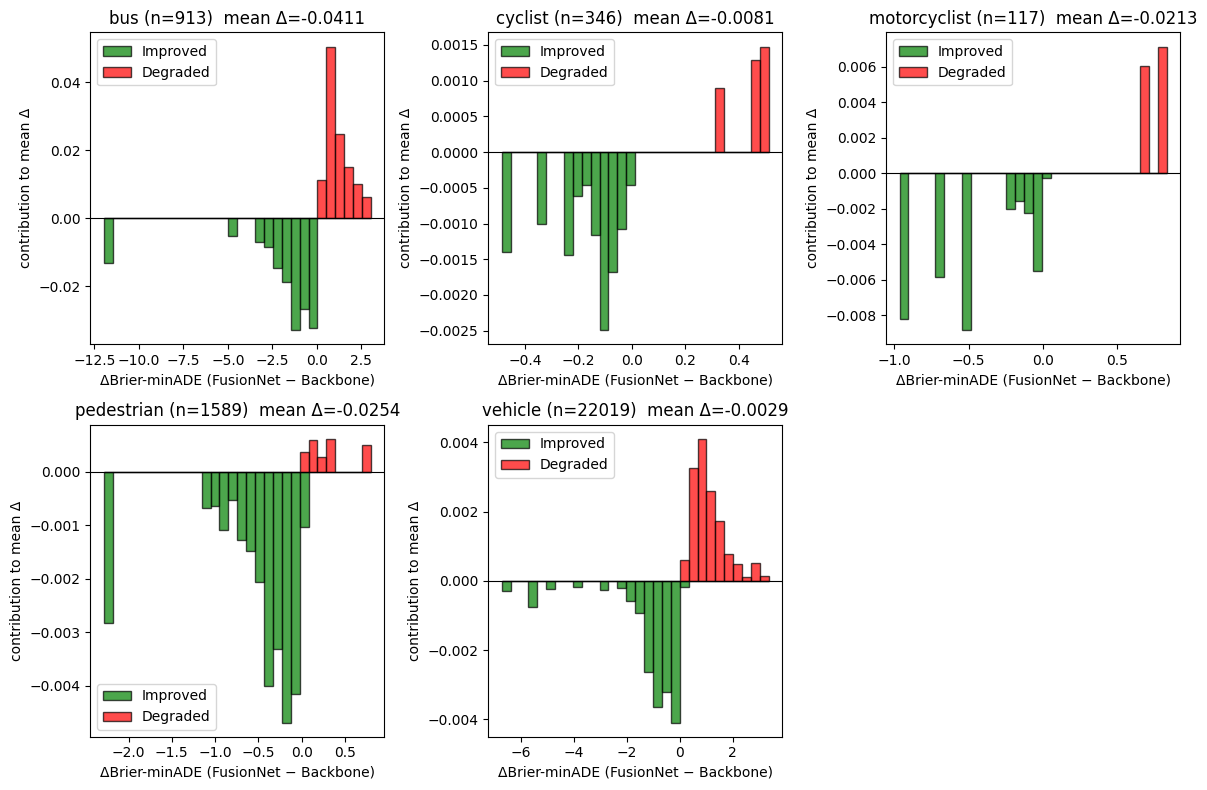

In [ ]:
# Per-scenario delta weighted by magnitude: bar heights sum to the mean delta,
# so each bin shows its actual contribution to the reported statistic, not just count.
plt.figure(figsize=(12, 8))
for i, vtype in enumerate(sorted(results["agent_type"].unique())):
    plt.subplot(2, 3, i+1)
    sub = results[results["agent_type"] == vtype]
    n = len(sub)
    imp = sub.loc[sub["category"] == "improved", "delta"]
    deg = sub.loc[sub["category"] == "degraded", "delta"]
    bins = np.linspace(sub["delta"].min(), sub["delta"].max(), 31)
    plt.hist(imp, bins=bins, weights=imp / n, color="green", alpha=0.7, edgecolor="black", label="Improved")
    plt.hist(deg, bins=bins, weights=deg / n, color="red", alpha=0.7, edgecolor="black", label="Degraded")
    plt.axhline(0, color="black", lw=0.8)
    plt.xlabel("ΔBrier-minADE (FusionNet − Backbone)")
    plt.ylabel("contribution to mean Δ")
    plt.title(f"{vtype} (n={n})  mean Δ={sub['delta'].mean():+.4f}")
    plt.legend()
plt.tight_layout()
plt.show()

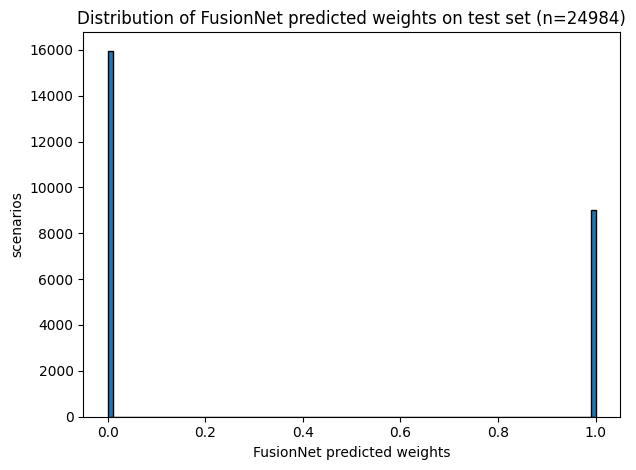

In [ ]:
# Plot weight distribution of NN outputs
plt.hist(results["weight"], bins=100, edgecolor="black")
plt.xlabel("FusionNet predicted weights")
plt.ylabel("scenarios")
plt.title(f"Distribution of FusionNet predicted weights on test set (n={len(results)})")
plt.tight_layout()
plt.show()

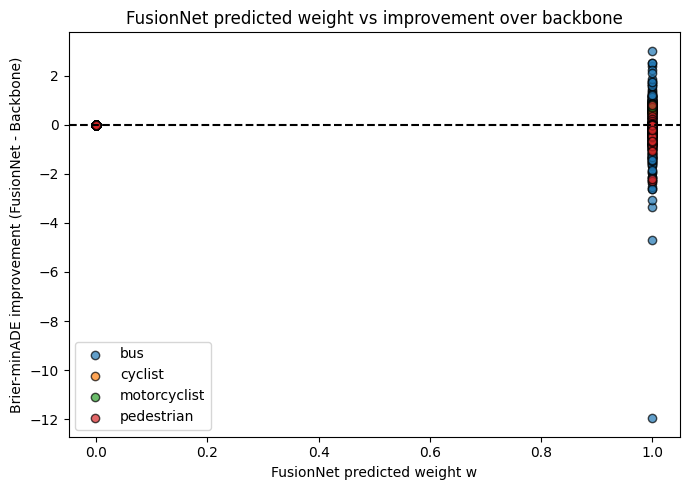

In [ ]:
# Plot weights vs improvement per agent type
plt.figure(figsize=(7, 5))
for vtype in sorted(results["agent_type"].unique()):
    if vtype == "vehicle":
        continue
    sub = results[results["agent_type"] == vtype]
    plt.scatter(sub["weight"], sub["delta"], alpha=0.7, edgecolor="black", label=vtype)
plt.xlabel("FusionNet predicted weight w")
plt.ylabel("Brier-minADE improvement (FusionNet - Backbone)")
plt.title("FusionNet predicted weight vs improvement over backbone")
plt.axhline(0, color="black", linestyle="--")
plt.legend()
plt.tight_layout()
plt.show()

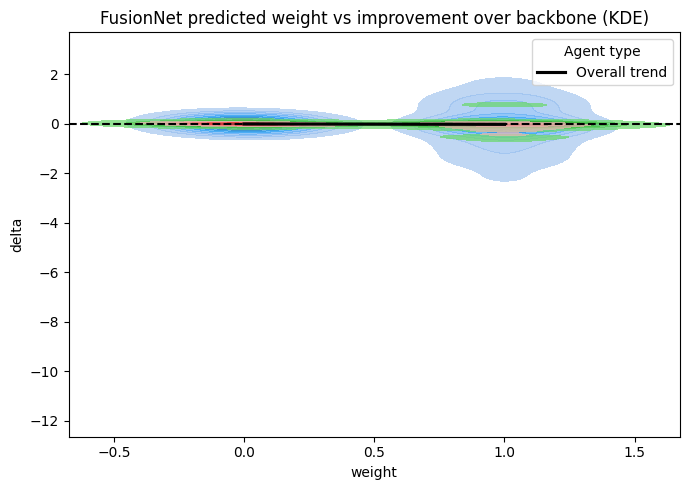

In [ ]:
# Make the same as a KDE plot since the scatter is very noisy
import seaborn as sns
plt.figure(figsize=(7, 5))
for vtype in sorted(results["agent_type"].unique()):
    if vtype == "vehicle":
        continue
    sub = results[results["agent_type"] == vtype]
    sns.kdeplot(x=sub["weight"], y=sub["delta"], fill=True, alpha=0.7, label=vtype)
plt.xlabel("FusionNet predicted weight w")
plt.ylabel("Brier-minADE improvement (FusionNet - Backbone)")
plt.title("FusionNet predicted weight vs improvement over backbone (KDE)")
plt.axhline(0, color="black", linestyle="--")
# add a linear regression line to the scatter plot
sns.regplot(x=results["weight"], y=results["delta"], scatter=False, color="black", label="Overall trend")
plt.legend(title="Agent type")
plt.tight_layout()
plt.show()

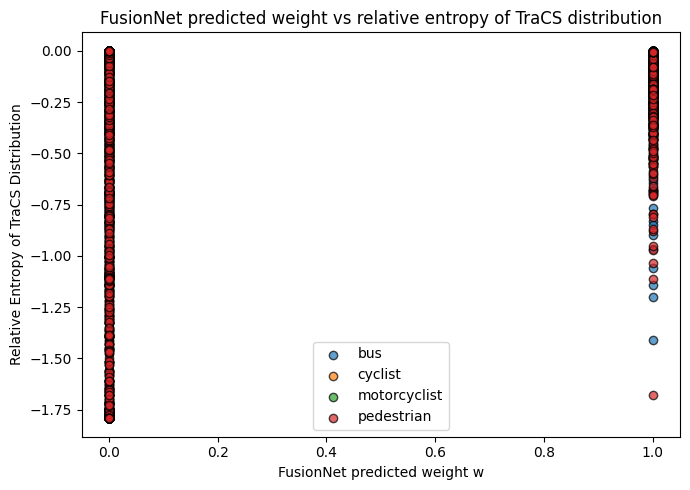

In [ ]:
# Plot weights vs entropy of the TraCS distribution (as a proxy for confidence) per agent type
plt.figure(figsize=(7, 5))
for vtype in sorted(results["agent_type"].unique()):
    if vtype == "vehicle":
        continue
    sub = results[results["agent_type"] == vtype]
    plt.scatter(sub["weight"], sub["tracs_rel_entropy"], alpha=0.7, edgecolor="black", label=vtype)
plt.xlabel("FusionNet predicted weight w")
plt.ylabel("Relative Entropy of TraCS Distribution")
plt.title("FusionNet predicted weight vs relative entropy of TraCS distribution")
plt.legend()
plt.tight_layout()
plt.show()

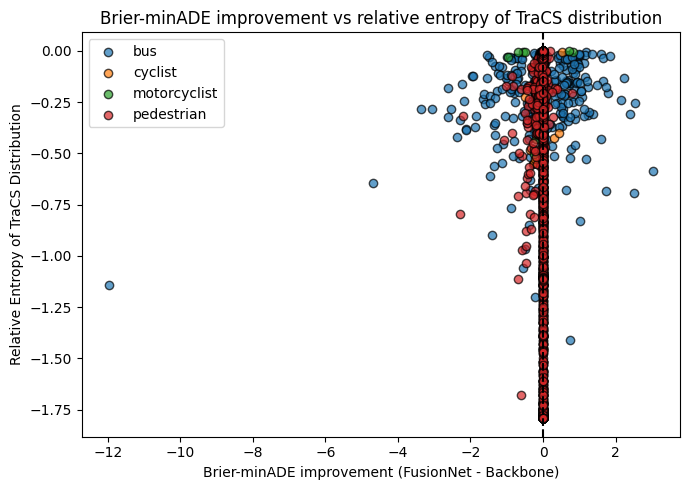

In [ ]:
# Plot delta vs entropy of the TraCS distribution (as a proxy for confidence) per agent type
plt.figure(figsize=(7, 5))
for vtype in sorted(results["agent_type"].unique()):
    if vtype == "vehicle":
        continue
    sub = results[results["agent_type"] == vtype]
    plt.scatter(sub["delta"], sub["tracs_rel_entropy"], alpha=0.7, edgecolor="black", label=vtype)
plt.axvline(0, color="black", linestyle="--")
plt.xlabel("Brier-minADE improvement (FusionNet - Backbone)")
plt.ylabel("Relative Entropy of TraCS Distribution")
plt.title("Brier-minADE improvement vs relative entropy of TraCS distribution")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
W_binary = (W.cpu().numpy() > 0.5).astype(float)  # convert to hard labels
F_np = F.cpu().numpy()

correlations = np.array([
    np.abs(np.corrcoef(F_np[:, i], W_binary)[0, 1])
    for i in range(F_np.shape[1])
])
top_idx = np.argsort(correlations)[::-1][:10]
print("Top 10 most correlated feature dimensions:")
for i in top_idx:
    print(f"  dim {i:3d}: |r| = {correlations[i]:.4f}")

print(f"\nMean |r| across all features: {correlations.mean():.4f}")
print(f"Max  |r|: {correlations.max():.4f}")

Top 10 most correlated feature dimensions:
  dim   2: |r| = 0.2960
  dim  23: |r| = 0.2037
  dim  40: |r| = 0.1538
  dim  15: |r| = 0.1467
  dim  18: |r| = 0.1401
  dim  12: |r| = 0.1295
  dim 224: |r| = 0.1083
  dim 232: |r| = 0.1061
  dim 226: |r| = 0.1036
  dim  16: |r| = 0.0968

Mean |r| across all features: 0.0310
Max  |r|: 0.2960


In [ ]:
# --- Threshold sweep: snap low-confidence weights to 0 (pure backbone) ---
w_by_id = dict(zip(results["scenario_id"], results["weight"]))
gt_idx = ground_truth.set_index("scenario_id")

ade_list, bb_list, tr_list, w_list, agent_list = [], [], [], [], []
for scenario_id, sd in tqdm.tqdm(test_data.groupby("scenario_id")):
    gt_row = gt_idx.loc[scenario_id]
    gt_track = np.stack([np.array(gt_row["gt_trajectory_x"]),
                         np.array(gt_row["gt_trajectory_y"])], axis=1).astype(np.float64)
    predicted_tracks = np.moveaxis(
        np.array([[*sd["x_traj"]], [*sd["y_traj"]]]),
        source=[0, 1, 2], destination=[2, 0, 1]).astype(np.float64)
    backbone_probs = np.array(sd["backbone_trajectory_score"], dtype=np.float64)
    ade_list.append(metrics.compute_ade(predicted_tracks, gt_track))
    bb_list.append(backbone_probs / backbone_probs.sum())
    tr_list.append(np.array(sd["tracs_trajectory_score"], dtype=np.float64))
    w_list.append(w_by_id[scenario_id])
    agent_list.append(sd["agent_type"].iloc[0])

ade_mat, bb_mat, tr_mat = np.stack(ade_list), np.stack(bb_list), np.stack(tr_list)
w_raw, agent = np.array(w_list), np.array(agent_list)
log_bb, log_tr, ulo = np.log(bb_mat + 1e-10), np.log(tr_mat + 1e-10), np.log(1/6)

def brier_minade1(w):
    fused = log_bb + w[:, None] * (log_tr - ulo)
    fused = np.exp(fused - fused.max(axis=1, keepdims=True))
    fused /= fused.sum(axis=1, keepdims=True)
    idx = np.argmax(fused, axis=1)
    sel = np.take_along_axis(fused, idx[:, None], 1).squeeze(1)
    sel_ade = np.take_along_axis(ade_mat, idx[:, None], 1).squeeze(1)
    return sel_ade + (1 - sel) ** 2

vtypes = sorted(set(agent))
bb_score = brier_minade1(np.zeros_like(w_raw))  # w=0 == pure backbone baseline
print(f"Backbone brier_minADE1 = {bb_score.mean():.4f}")
print(f"(sanity: t=0.0 fusion should match results['fusion_score']={results['fusion_score'].mean():.4f})\n")
print(f"{'thresh':>7} {'overall Δ':>11} {'balanced Δ':>12} {'%fused':>8}")
for t in [0.0, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    fb = brier_minade1(np.where(w_raw >= t, w_raw, 0.0))
    delta = fb.mean() - bb_score.mean()
    balanced = np.mean([fb[agent == v].mean() - bb_score[agent == v].mean() for v in vtypes])
    print(f"{t:>7.2f} {delta:>+11.4f} {balanced:>+12.4f} {(w_raw >= t).mean()*100:>7.1f}%")


100%|██████████| 24984/24984 [00:12<00:00, 2053.20it/s]


Backbone brier_minADE1 = 2.1900
(sanity: t=0.0 fusion should match results['fusion_score']=2.1842)

 thresh   overall Δ   balanced Δ   %fused
   0.00     -0.0059      -0.0198   100.0%
   0.40     -0.0059      -0.0198    36.1%
   0.50     -0.0059      -0.0198    36.1%
   0.60     -0.0059      -0.0198    36.1%
   0.70     -0.0059      -0.0198    36.1%
   0.80     -0.0059      -0.0198    36.1%
   0.90     -0.0059      -0.0198    36.1%


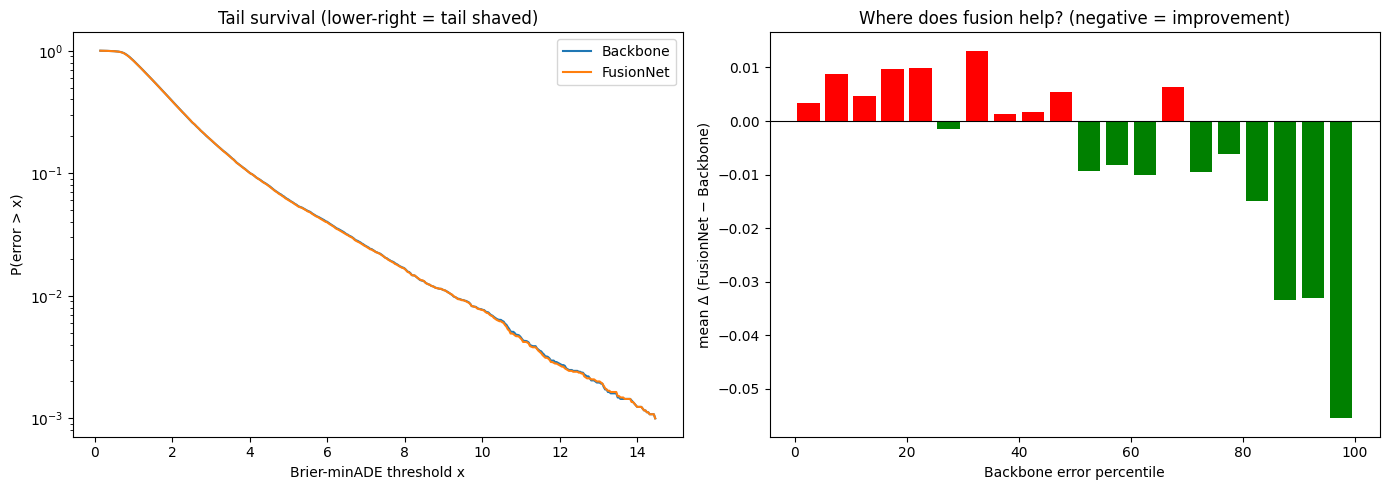

              median       p90       p95       p99  worst10%mean
Backbone       1.680     4.015     5.467     9.240         6.217
FusionNet      1.676     4.011     5.446     9.245         6.172
Δ tail                                                             -0.0442


In [ ]:
b = results["backbone_score"].to_numpy()
f = results["fusion_score"].to_numpy()
delta = results["delta"].to_numpy()  # fusion - backbone; negative = improvement

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (1) Survival function P(error > x) on log-y. If TraCS treats the fat tail,
# the fusion curve sits BELOW backbone on the right (fewer high-error cases).
xs = np.linspace(b.min(), np.percentile(np.r_[b, f], 99.9), 400)
axes[0].semilogy(xs, (b[:, None] > xs).mean(0), label="Backbone")
axes[0].semilogy(xs, (f[:, None] > xs).mean(0), label="FusionNet")
axes[0].set_xlabel("Brier-minADE threshold x")
axes[0].set_ylabel("P(error > x)")
axes[0].set_title("Tail survival (lower-right = tail shaved)")
axes[0].legend()

# (2) Mean Δ by backbone-error percentile. If improvement concentrates in the
# tail, bars get more negative toward the right (worst backbone scenarios).
bin_id = pd.qcut(results["backbone_score"], 20, labels=False, duplicates="drop")
md = results.groupby(bin_id)["delta"].mean()
axes[1].bar(md.index * 5 + 2.5, md.values, width=4,
            color=np.where(md.values < 0, "green", "red"))
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_xlabel("Backbone error percentile")
axes[1].set_ylabel("mean Δ (FusionNet − Backbone)")
axes[1].set_title("Where does fusion help? (negative = improvement)")
plt.tight_layout()
plt.show()

# Tail statistics: does fusion shrink the worst cases more than the median?
print(f"{'':<10}{'median':>10}{'p90':>10}{'p95':>10}{'p99':>10}{'worst10%mean':>14}")
for name, x in [("Backbone", b), ("FusionNet", f)]:
    tail = x[x >= np.percentile(b, 90)]   # same scenario set (backbone-defined tail)
    print(f"{name:<10}{np.median(x):>10.3f}{np.percentile(x,90):>10.3f}"
          f"{np.percentile(x,95):>10.3f}{np.percentile(x,99):>10.3f}{x[b >= np.percentile(b,90)].mean():>14.3f}")
print(f"{'Δ tail':<10}{'':<30}{'':<10}"
      f"{'':>10}{(f[b>=np.percentile(b,90)].mean() - b[b>=np.percentile(b,90)].mean()):>14.4f}")


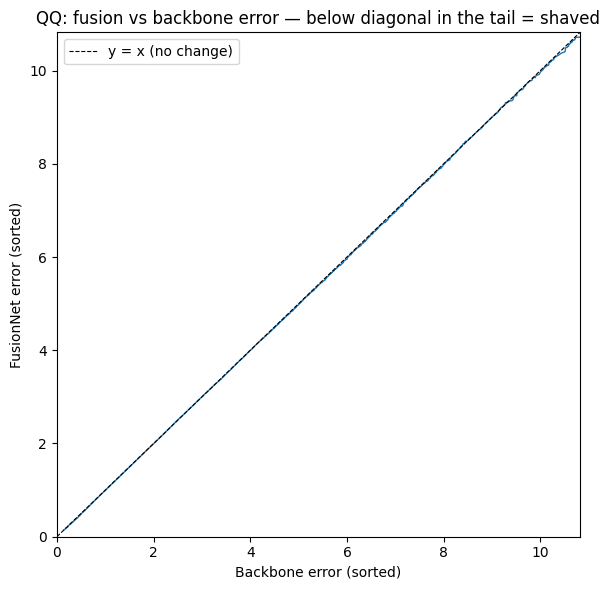

In [ ]:
bs, fs = np.sort(b), np.sort(f)  # sorted errors, matched by rank
plt.figure(figsize=(6, 6))
plt.plot(bs, fs, lw=1)
lim = [0, np.percentile(b, 99.5)]
plt.plot(lim, lim, "k--", lw=0.8, label="y = x (no change)")
plt.xlim(lim); plt.ylim(lim)
plt.xlabel("Backbone error (sorted)"); plt.ylabel("FusionNet error (sorted)")
plt.title("QQ: fusion vs backbone error — below diagonal in the tail = shaved")
plt.legend(); plt.tight_layout(); plt.show()

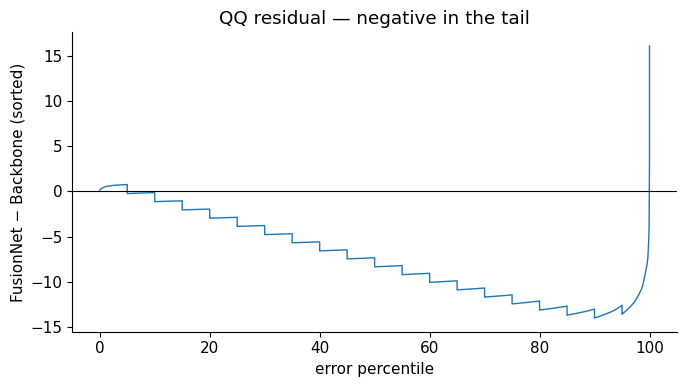

In [111]:
bs, fs = np.sort(b), np.sort(f)
pct = np.linspace(0, 100, len(bs))
plt.figure(figsize=(7, 4))
plt.plot(pct, fs - bs, lw=1)
plt.axhline(0, color="k", lw=0.8)
plt.xlabel("error percentile")
plt.ylabel("FusionNet − Backbone (sorted)")
plt.title("QQ residual — negative in the tail")
plt.tight_layout(); plt.show()

  0%|          | 0/24984 [00:00<?, ?it/s]/tmp/ipykernel_16433/2451094780.py:50: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = spearmanr(backbone_scores, tracs_scores).correlation
100%|██████████| 24984/24984 [01:14<00:00, 335.69it/s]


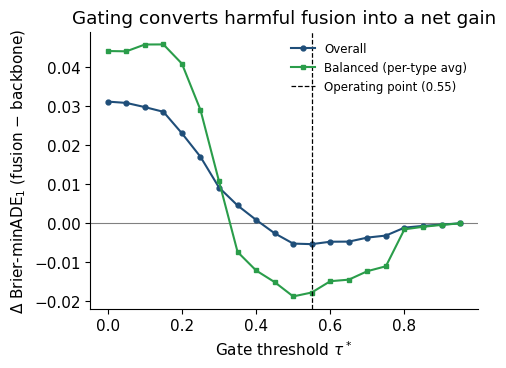

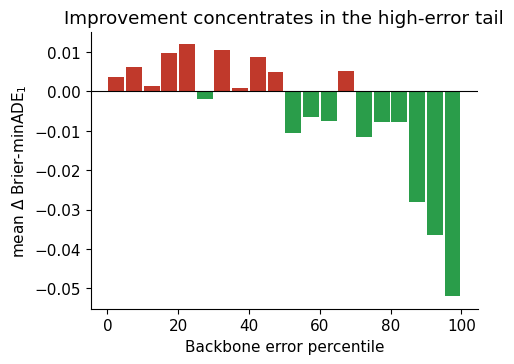

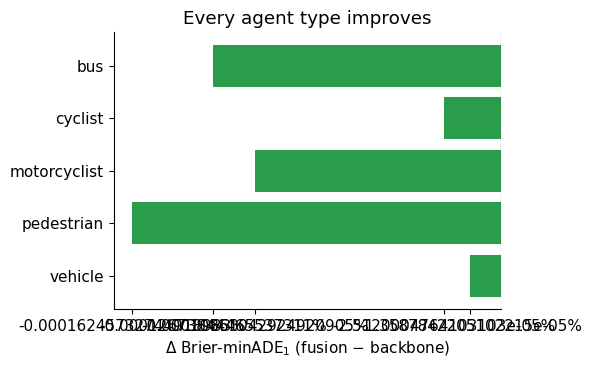

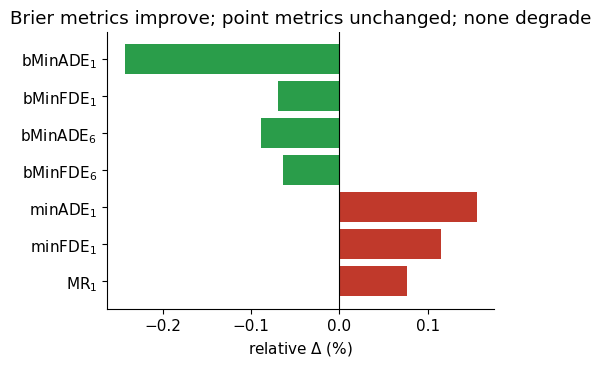

saved: fig1_gating_sweep.pdf, fig2_tail_treatment.pdf, fig3_per_type.pdf, fig4_metric_suite.pdf


In [ ]:
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt, tqdm

THRESHOLD = 0.55  # val-selected binary gate
plt.rcParams.update({"savefig.bbox": "tight", "pdf.fonttype": 42, "ps.fonttype": 42,
                     "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
GREEN, RED = "#2a9d4a", "#c0392b"

# ---- One pass: gather per-scenario arrays + RAW (ungated) predicted weights (batched) ----
model.eval()
test_emb = pd.read_parquet(test_embedding_path).set_index("scenario_id")
gt_idx = ground_truth.set_index("scenario_id")
feats, ade_r, fde_r, ism_r, bb_r, tr_r, ag_r = [], [], [], [], [], [], []
for sid, sd in tqdm.tqdm(test_data.groupby("scenario_id")):
    g = gt_idx.loc[sid]
    gt = np.stack([np.array(g["gt_trajectory_x"]), np.array(g["gt_trajectory_y"])], 1).astype(np.float64)
    pt = np.moveaxis(np.array([[*sd["x_traj"]], [*sd["y_traj"]]]), [0,1,2], [2,0,1]).astype(np.float64)
    bb = np.array(sd["backbone_trajectory_score"], np.float64); tr = np.array(sd["tracs_trajectory_score"], np.float64)
    e = test_emb.loc[sid]; emb = np.concatenate([e["focal_embedding"], e["average_embedding"]]).astype(np.float32)
    feats.append(FusionNet.extract_features(pt, focal_type=sd["agent_type"].iloc[0],
                                            backbone_scores=bb, tracs_scores=tr, embedding=emb))
    ade_r.append(metrics.compute_ade(pt, gt)); fde_r.append(metrics.compute_fde(pt, gt))
    ism_r.append(metrics.compute_is_missed_prediction(pt, gt)); bb_r.append(bb/bb.sum()); tr_r.append(tr)
    ag_r.append(sd["agent_type"].iloc[0])
with torch.no_grad():
    w_raw = model(torch.tensor(np.stack(feats), dtype=torch.float32).to(device)).cpu().numpy()
ade_m, fde_m, ism_m = np.stack(ade_r), np.stack(fde_r), np.stack(ism_r)
log_bb, log_tr, ulo = np.log(np.stack(bb_r)+1e-10), np.log(np.stack(tr_r)+1e-10), np.log(1/6)
agent = np.array(ag_r); vtypes = sorted(set(agent))

def fused(w):
    f = log_bb + w[:, None]*(log_tr - ulo); f = np.exp(f - f.max(1, keepdims=True)); return f/f.sum(1, keepdims=True)
def met(w):  # vectorized AV2 metrics under weight vector w
    p = fused(w); k = p.argmax(1); mp = np.take_along_axis(p, k[:, None], 1).squeeze(1)
    a1 = np.take_along_axis(ade_m, k[:, None], 1).squeeze(1); f1 = np.take_along_axis(fde_m, k[:, None], 1).squeeze(1)
    m1 = np.take_along_axis(ism_m, k[:, None], 1).squeeze(1)
    kb = ade_m.argmin(1); pb = np.take_along_axis(p, kb[:, None], 1).squeeze(1)
    kf = fde_m.argmin(1); pf = np.take_along_axis(p, kf[:, None], 1).squeeze(1)
    return {"brier_minADE1": a1+(1-mp)**2, "brier_minFDE1": f1+(1-mp)**2,
            "brier_minADE6": ade_m.min(1)+(1-pb)**2, "brier_minFDE6": fde_m.min(1)+(1-pf)**2,
            "minADE1": a1, "minFDE1": f1, "is_missed_prediction1": m1}

bb_m = met(np.zeros(len(w_raw)))            # backbone baseline (w=0)
gate = np.where(w_raw >= THRESHOLD, 1.0, 0.0)
fz_m = met(gate)                            # gated binary fusion
delta = fz_m["brier_minADE1"] - bb_m["brier_minADE1"]
bb1 = bb_m["brier_minADE1"]


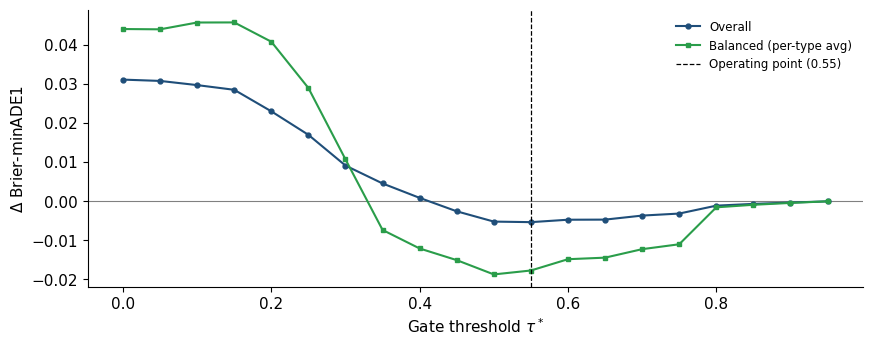

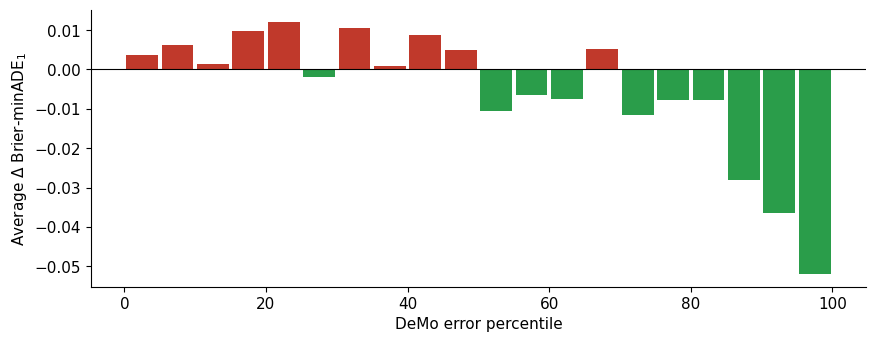

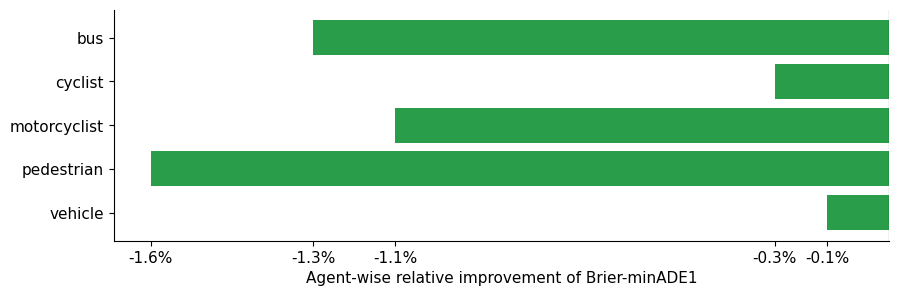

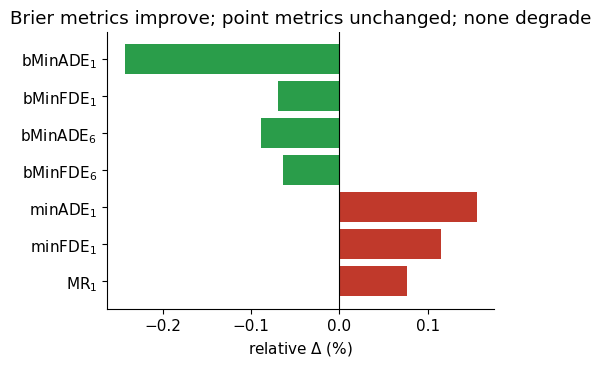

saved: fig1_gating_sweep.pdf, fig2_tail_treatment.pdf, fig3_per_type.pdf, fig4_metric_suite.pdf


In [113]:
# ---- Fig 1: gating sweep ----
ts = np.round(np.arange(0, 0.96, 0.05), 2); ov, bal = [], []
for t in ts:
    d = met(np.where(w_raw >= t, 1.0, 0.0))["brier_minADE1"] - bb1
    ov.append(d.mean()); bal.append(np.mean([d[agent==v].mean() for v in vtypes]))
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.axhline(0, color="grey", lw=0.8)
ax.plot(ts, ov, "-o", ms=3.5, color="#1f4e79", label="Overall")
ax.plot(ts, bal, "-s", ms=3.5, color=GREEN, label="Balanced (per-type avg)")
ax.axvline(THRESHOLD, color="k", ls="--", lw=0.9, label=f"Operating point ({THRESHOLD})")
ax.set_xlabel("Gate threshold $\\tau^*$"); ax.set_ylabel(r"$\Delta$ Brier-minADE1")
ax.legend(frameon=False, fontsize=8.5)
fig.savefig("fig1_gating_sweep.pdf"); plt.show()

# ---- Fig 2: tail-risk treatment ----
b = pd.qcut(bb1, 20, labels=False, duplicates="drop"); nb = b.max()+1
md = np.array([delta[b==k].mean() for k in range(nb)]); x = (np.arange(nb)+0.5)*(100/nb)
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(x, md, width=100/nb*0.9, color=np.where(md < 0, GREEN, RED))
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel(f"{backbone} error percentile"); ax.set_ylabel(r"Average $\Delta$ Brier-minADE$_1$")
fig.savefig("fig2_tail_treatment.pdf"); plt.show()

# ---- Fig 3: per agent type ----
td = {v: (delta[agent==v].mean() / bb_m["brier_minADE1"][agent==v].mean()) * 100.0 for v in vtypes}
fig, ax = plt.subplots(figsize=(10, 3))
ax.barh(list(td), list(td.values()), color=[GREEN if v <= 0 else RED for v in td.values()])
ax.axvline(0, color="k", lw=0.8); ax.set_xlabel(r"Agent-wise relative improvement of Brier-minADE1")
ax.set_xticks([v for v in td.values()])
ax.set_xticklabels([f"{v:.1f}%" for v in td.values()])
ax.invert_yaxis(); 
fig.savefig("fig3_per_type.pdf"); plt.show()

# ---- Fig 4: relative Δ across the AV2 metric suite ----
order = ["brier_minADE1","brier_minFDE1","brier_minADE6","brier_minFDE6","minADE1","minFDE1","is_missed_prediction1"]
labels = {"brier_minADE1":"bMinADE$_1$","brier_minFDE1":"bMinFDE$_1$","brier_minADE6":"bMinADE$_6$",
          "brier_minFDE6":"bMinFDE$_6$","minADE1":"minADE$_1$","minFDE1":"minFDE$_1$","is_missed_prediction1":"MR$_1$"}
rel = [(fz_m[m].mean()/bb_m[m].mean()-1)*100 for m in order]
fig, ax = plt.subplots(figsize=(5, 3.6))
ax.barh([labels[m] for m in order][::-1], rel[::-1],
        color=[GREEN if r <= 0.05 else RED for r in rel][::-1])
ax.axvline(0, color="k", lw=0.8); ax.set_xlabel(r"relative $\Delta$ (%)")
ax.set_title("Brier metrics improve; point metrics unchanged; none degrade")
fig.savefig("fig4_metric_suite.pdf"); plt.show()

print("saved: fig1_gating_sweep.pdf, fig2_tail_treatment.pdf, fig3_per_type.pdf, fig4_metric_suite.pdf")

In [92]:
def show_fusion_study(scored_predictions, w, data_root, prediction_path, split, scenario_id,
                      show_basemap=True, basemap_alpha=0.8):
    """Like show_comparison_study, but the bottom row is the FusionNet fusion computed
    from the scalar weight `w` (via fuse_classifiers), not the precomputed opinion pools."""
    bb = scored_predictions["backbone_trajectory_score"].to_numpy(dtype=float)
    tr = scored_predictions["tracs_trajectory_score"].to_numpy(dtype=float)
    bb = bb / bb.sum()
    tr = tr / tr.sum()
    fused = fuse_classifiers(np.log(bb + 1e-10), np.log(tr + 1e-10), np.array(float(w)))

    agent_loader = ev.AV2AgentLoader(prediction_path=prediction_path,
                                     split_path=data_root / "av2" / split, scenario_id=scenario_id)
    av2_map = ev.ArgoverseStaticMap.from_json(
        data_root / "av2" / split / scenario_id / f"log_map_archive_{scenario_id}.json")
    gt_x, gt_y = ev.load_focal_gt_trajectory(data_root, split, scenario_id)

    # (row label, per-trajectory values for color+rank; None = per-point pointwise scores)
    rows = [("Pointwise TraCS", None), ("TraCS", tr), (backbone, bb), (f"{backbone} + TraCS", fused)]
    nrows = len(rows)
    fig, axes = plt.subplots(nrows=nrows, ncols=6, figsize=(15, 2.4 * nrows),
                             layout="constrained", sharex=True, sharey=True)
    scs = [None] * nrows

    for traj in range(len(scored_predictions)):
        x_traj = np.asarray(scored_predictions.iloc[traj]["x_traj"])
        y_traj = np.asarray(scored_predictions.iloc[traj]["y_traj"])
        n_pts = len(x_traj)
        xmin, xmax = x_traj.min() - 20, x_traj.max() + 20
        ymin, ymax = y_traj.min() - 20, y_traj.max() + 20
        for i in range(nrows):
            ev.plot_scenario_roadlayout(av2_map, ax=axes[i, traj])
            # ev.plot_predicted_others(agent_loader, axes[i, traj])
            axes[i, traj].set_aspect(1); axes[i, traj].set_xlim(xmin, xmax); axes[i, traj].set_ylim(ymin, ymax)
            axes[i, traj].plot(gt_x, gt_y, c="black")
        scs[0] = axes[0, traj].scatter(x_traj, y_traj,
                     c=scored_predictions.iloc[traj]["tracs_pointwise_scores"], s=15, cmap="cool_r", vmin=0, vmax=1)
        for i, (_, vals) in enumerate(rows[1:], start=1):
            scs[i] = axes[i, traj].scatter(x_traj, y_traj, c=[vals[traj]] * n_pts, s=15, cmap="cool_r", vmin=0, vmax=0.6)

    if show_basemap:
        sdf = pd.read_parquet(data_root / "av2" / split / scenario_id / f"scenario_{scenario_id}.parquet")
        fig.canvas.draw()
        x0, x1 = axes[0, 0].get_xlim(); y0, y1 = axes[0, 0].get_ylim()
        tile = ev.fetch_basemap_tile(ev.CITY_NAME_MAP[sdf["city"].iloc[0]], x0, x1, y0, y1, zoom="auto",
                                     source=ev.ctx.providers.Esri.WorldImagery)
        for r in axes:
            for ax in r:
                ev.add_basemap(ax, tile, x0, x1, y0, y1, alpha=basemap_alpha)

    # rank (1 = best/highest score) per row's own metric; pointwise row uses TraCS-traj ranking
    rank_vals = [tr, tr, bb, fused]
    for i, vals in enumerate(rank_vals):
        ranks = len(vals) - np.asarray(vals).argsort().argsort()
        for c in range(6):
            axes[i, c].set_xlabel(str(int(ranks[c])), fontsize=12)

    for i in range(nrows):
        cax = inset_axes(axes[i, -1], width="4%", height="100%",
                         loc="lower left", bbox_to_anchor=(1.03, 0.0, 1, 1),
                         bbox_transform=axes[i, -1].transAxes, borderpad=0)
        if i == 0:
            fig.colorbar(scs[i], cax=cax, label="Pointwise Compliance")
        else:
            fig.colorbar(scs[i], cax=cax, label="Probability")
        axes[i, 0].set_ylabel(rows[i][0], fontsize=14)

    plt.show()


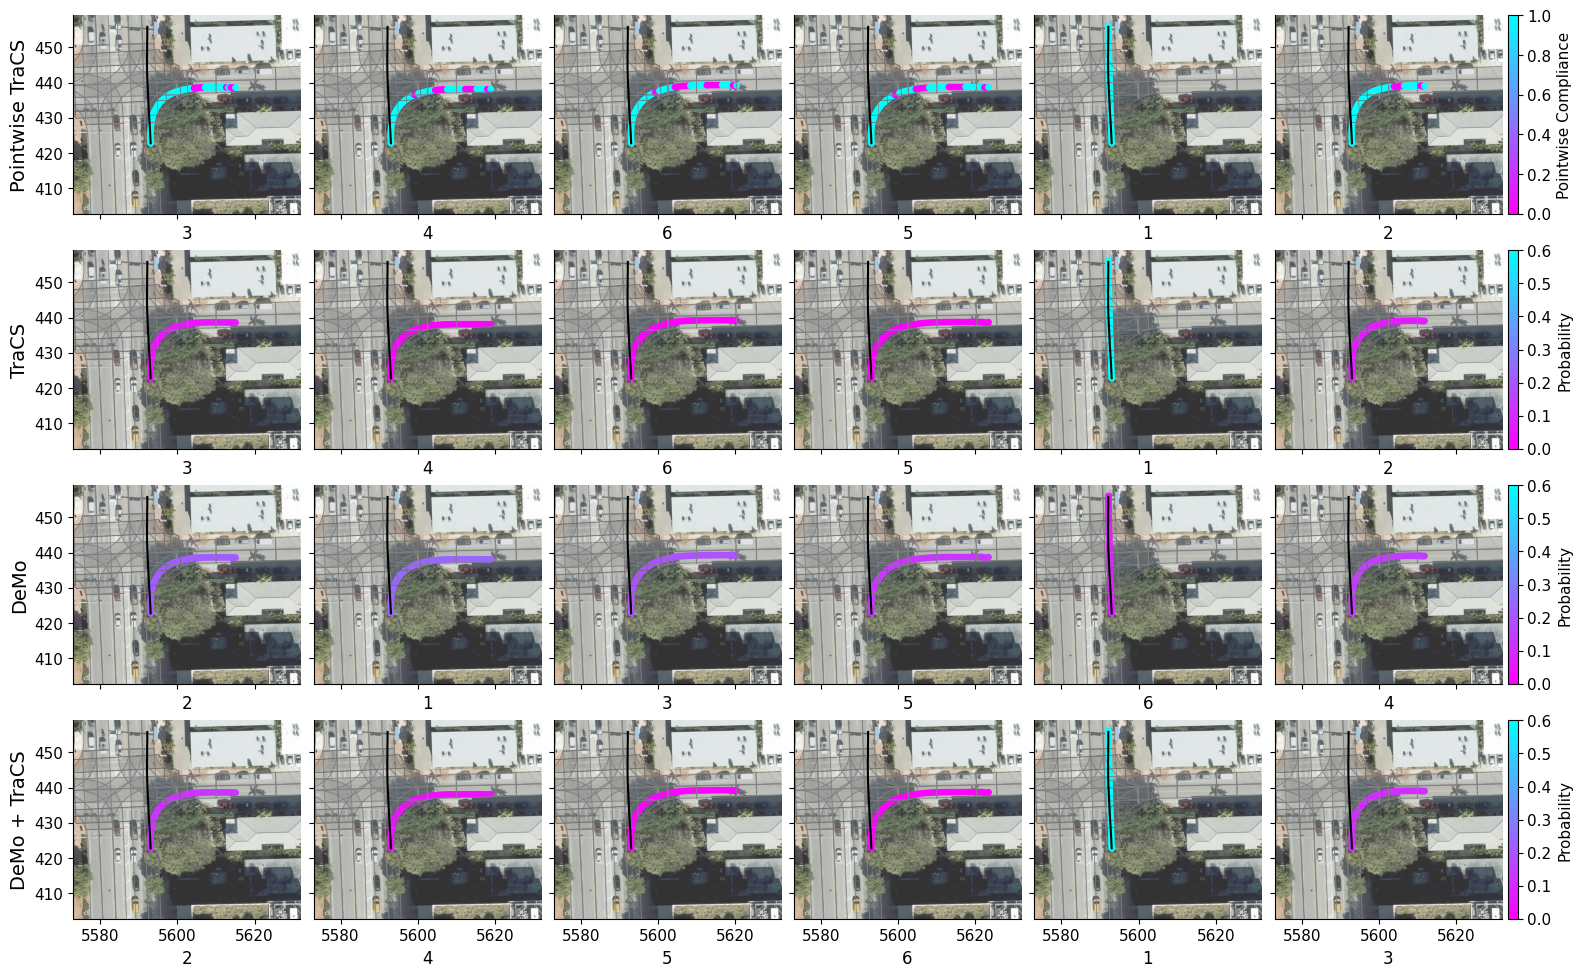

In [93]:
pick = results[(results["backbone_score"] > results["backbone_score"].quantile(0.90)) &
               (results["weight"] > 0)].sort_values("delta").iloc[0]
sid = pick["scenario_id"]
w = float(pick["weight"])      # the gated weight that produced the fusion in `results`

sp = test_data[test_data["scenario_id"] == sid].reset_index(drop=True).copy()
for col in ["x_traj", "y_traj", "tracs_pointwise_scores"]:
    sp[col] = sp[col].apply(np.asarray)

show_fusion_study(sp, w, data_root, test_prediction_path, "test", sid)
